# 03 · Train: can bge-large learn the course?

*For learning. Nothing here runs in CI and nothing leaves this computer: the datasets registered by stage 1 on the local
MLflow server (`http://localhost:5050`, experiment `coach-retrieval-lab`), `bge-large` from the Hugging Face cache, Ollama
(`qwen3:14b`) for rewriting training questions, and this computer's GPU for training.*

**What this notebook settles, on the dev split only.** Can fine-tuning `bge-large` on the course beat `bge-large` as its
makers ship it (the champion) on **learner-worded questions about lessons it never trained on**, without **forgetting** the
course-worded ones? Fine-tuning means: start from the model's own weights and keep training it a little on our own
examples, so it gets better at our job without learning language from scratch.

**Which split it uses.** Training rows come only from the 123 **train** lessons. The 42 **dev** lessons are used to watch
the curves, pick a checkpoint and pick the settings, nothing else. **Test** (29 lessons) stays closed until stage 4, and the
**holdout** (18 lessons) stays locked (`retrieval.score` refuses it). So every number here is a dev number, and dev has been
used to choose: the clean number is stage 4's.

**Two things said plainly before any number.**

* **`embeddinggemma` cannot be fine-tuned on this computer.** Its weights are gated on Hugging Face (you accept the makers'
  terms with an account) and there is no token here, so the files cannot be fetched. It stays a challenger **as its makers
  ship it**, for stage 4. That is a fact about access, not about the model.
* **The honest test was read by Claude, not by a person.** `honest_dev` is `qwen3:14b` rewrites of the dev Check and
  practice questions; Claude read them at the owner's request and 11 were dropped across dev and test; a few new ones are
  unread. Every honest number below carries that caveat.

**The lessons applied.** Where the course has a lesson for a habit, its title is in the heading: *Train, validation and test
data*, *Retrieval: finding the right chunks*, *What an embedding is: meaning as a place*, *Dev, test and holdout sets*,
*Telling real gains from noise*, *Margins near 0% and 100%*, *The cost of embeddings*, *Comparing on the same examples*,
*Embedding models have blind spots*. The course has no lesson on learning rates or overfitting; those are explained here in
plain words.

**How to work through it.** Before each result there is a cell for **your guess**: write it down, then run the next cell.
Your guesses go into the MLflow run beside the real answers. The exercises have blanks (`"___"`); the answers are in
`03_train_answers.py`, which `DRILL_FILL_ANSWERS=1` uses to check the notebook runs end to end. The long code is in
`training.py` and `retrieval.py`, so the cells stay short.

**How long it takes.** About 45 minutes (42 minutes on 2026-11-08, with all 365 rewrites): five full-length training runs
of about seven and a half minutes each (156 steps at 2 s a step, with gradient checkpointing on; the LoRA run is a little
quicker), the overfit run (4 minutes), dev scored every 20 steps (12 s each time), and the paraphrase pass, which is cached
after the first time. Another job using Ollama at the same time makes every step slower (section 0 explains the memory
guard).

> **In plain words: two meanings of "token", and Hugging Face.** In "there is no token here", a **token** is an access key: a secret
> string that proves to Hugging Face who you are, like a password for programs (*Short-lived tokens, not PATs* covers that sense).
> Everywhere else in this lab a token is a word or a piece of one (*How an LLM works, in plain words*). **Hugging Face** is the
> website where makers publish model files; **gated** files need an account, accepted terms and that key, and the **cache** is the
> copy already downloaded here.

In [1]:
import importlib
import json
import os
import time
from collections import Counter
from pathlib import Path

os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT", "1")   # run links are printed short, by tracking.run_link
os.environ.setdefault("TQDM_DISABLE", "1")

import matplotlib
import mlflow
import pandas as pd
from drill.content import build_data

import retrieval as r
import tracking
import training as t

FILL = os.environ.get("DRILL_FILL_ANSWERS") == "1"      # only for checking the notebook end to end
answers = importlib.import_module("03_train_answers")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)


def attempt(value, name):
    # Your answer; if it still has a blank, a reminder (or, when checking the notebook end to end, the answer file's).
    if "___" not in str(value):
        return value
    if FILL:
        return getattr(answers, name)
    print("Fill in the ___ first, then run this cell again.")
    return None


def clip(text, n=110):
    return text if len(text) <= n else text[: n - 1] + "…"

## 0. Setup: the frozen data, the bar, and one parent run (*Dev, test and holdout sets*)

The data is read back from **stage 1's newest run** by name, and each table's digest (a fingerprint of every word in it) is
checked against the one stage 1 logged: if a single question moved, the cell stops. Then **stage 2's newest parent run**
gives the champion's dev numbers, which is the line every curve below is drawn against.

**The course has moved on since stage 1, and this notebook trains on stage 1's frozen copy on purpose.** The experiment
compares models on one fixed course. After stage 1 froze it, later content work reworded some Learn paragraphs, added a
few and dropped some prepared question chips. Stages 2 to 4 all measure against the frozen copy, so the training rows, the
paragraphs every dev question searches and the dev questions themselves all come from it, read from stage 1's MLflow run,
never from today's course. Training on today's course and judging on the frozen one would mix two courses in one result.
Today's course is read for three checks only, which replace the old "the fingerprint must equal stage 1's" line (that
line could only say *something* changed, not whether it mattered here):

1. a fresh deal of today's course puts every lesson in the split `data/splits.json` has (0 lessons moved), and that file
   is the one stage 1 logged;
2. no train or dev Check or practice question is worded differently today from stage 1's `pairs_train` and `pairs_dev`;
3. the refusal list (a training question may never equal a dev, test or holdout question) holds today's questions and
   stage 1's dev questions together; it compares words only and scores nothing.

Both fingerprints (stage 1's and today's) and the counts of what changed are logged as params, so the record says which
content was trained on. *This is wrong if* a change since stage 1 moved a lesson between splits or reworded a question the
experiment trains or chooses on. Checks 1 and 2 stop the cell for a moved lesson or a reworded Check or practice
question, and only for those. The prepared chips (the option, term and explain rows, 802 of the 1,291 train and dev
rows) are not checked for rewording: the cell only counts the ones gone from today's course (72, logged as a param).
Training reads only stage 1's frozen rows, so this does not change what was trained or chosen on, but those rows no longer
all match the live course, and a reworded chip would not be caught here.

> **In plain words: digest and fingerprint.** A dataset's **digest** is a short code worked out from that dataset's rows and logged
> by MLflow with the dataset. The course **fingerprint** is a code worked out from every paragraph and question in the course. The
> digest is checked: it says this table did not move. The fingerprint is logged, not required to be equal: it changes when any paragraph is
> reworded, which happened after stage 1 and does not touch the frozen tables. What would spoil the experiment (a lesson moving
> split, a question it uses reworded) is checked directly, below.

In [2]:
tracking.connect()
s1 = t.load_stage1()   # pairs_train, pairs_dev, honest_dev, corpus: read from stage 1's run, each checked against stage 1's digest
stage1 = s1["run"]
stage2 = tracking.find_run(tracking.EXPERIMENT, "baselines · champion and the bar (dev)")
assert stage2.data.params["stage1_run_id"] == stage1.info.run_id, "stage 2's bar was set on an older split: rerun 02_baselines first"
splits = r.load_splits()
frozen_at_stage1 = r.load_splits(mlflow.artifacts.download_artifacts(run_id=stage1.info.run_id, artifact_path="splits.json"))
assert splits == frozen_at_stage1, "data/splits.json is not the split stage 1 logged: stop and look"

data = build_data()   # today's course: only for the checks below and the refusal list, never trained on or scored
moved = sorted(lid for lid, split in r.split_lessons(data).items() if splits.get(lid) != split) + sorted(set(splits) - set(data["lessons"]))
assert not moved, f"today's course deals {len(moved)} lessons differently ({moved[:5]}): the split moved, rerun stage 1 first"
pairs_now, corpus_now = r.build_pairs(data), r.build_corpus(data)
live = {p["id"]: p["question"] for p in pairs_now}
used = [p for name in ("pairs_train", "pairs_dev") for p in s1[name] if p["source"] in ("check", "more")]
reworded_q = sorted(p["id"] for p in used if live.get(p["id"]) != p["question"])
assert not reworded_q, f"{len(reworded_q)} train or dev Check/practice questions read differently today ({reworded_q[:5]}): stop and look"
fingerprint_stage1 = stage1.data.params["content_fingerprint"]
fingerprint_now = r.content_fingerprint(corpus_now, pairs_now)
fingerprint = fingerprint_stage1   # the content this notebook trains and chooses on
was, now = {c["id"]: c["text"] for c in s1["corpus"]}, {c["id"]: c["text"] for c in corpus_now}
frozen_prepared = {p["id"] for name in ("pairs_train", "pairs_dev") for p in s1[name] if p["source"] == "prepared"}
drift = {"paragraphs_reworded": sum(was[k] != now[k] for k in set(was) & set(now)), "paragraphs_added": len(set(now) - set(was)),
         "paragraphs_removed": len(set(was) - set(now)), "train_dev_questions_reworded": len(reworded_q),
         "train_dev_prepared_chips_gone": len(frozen_prepared - set(live)), "lessons_moved_split": len(moved)}
all_pairs = pairs_now + s1["pairs_dev"]   # the refusal list: no training question may equal one of these non-train questions (words only)

corpus, pairs_train, honest_dev, originals_dev = s1["corpus"], s1["pairs_train"], s1["honest_dev"], s1["originals_dev"]
dev_sets = {"honest": honest_dev, "originals": originals_dev}   # the same dev questions in a learner's words and in the course's
unread = sum(1 - int(h.get("checked", 0)) for h in honest_dev)
bar = {k: stage2.data.metrics[f"bar.champion.{k}"] for k in
       ("honest.recall_at_5", "honest.low", "honest.high", "originals.recall_at_5", "originals.low", "originals.high")}
print(f"stage 1 run {tracking.short(stage1.info.run_id)}; stage 2 run {tracking.short(stage2.info.run_id)}")
print(f"split (lessons): {r.split_counts(splits)}; unchanged in today's course (0 of {len(splits)} lessons move); "
      f"0 of the {len(used)} train and dev Check/practice questions read differently today")
print(f"course fingerprint: stage 1 {fingerprint_stage1}, today {fingerprint_now} "
      f"({'the same' if fingerprint_now == fingerprint_stage1 else 'changed since stage 1: this notebook trains on stage 1\'s snapshot'}); since stage 1: {drift}")
print(f"read from stage 1's run only: train pairs {len(pairs_train)}; dev honest {len(honest_dev)} ({unread} not read yet), "
      f"dev originals {len(originals_dev)}; corpus {len(corpus)} paragraphs (today's course has {len(corpus_now)})")
print("digests (each equal to stage 1's):", {name: ds.digest for name, (ds, _) in s1["datasets"].items()})
print(f"the champion on dev (stage 2): honest recall@5 {bar['honest.recall_at_5']:.3f} [{bar['honest.low']:.2f}, {bar['honest.high']:.2f}], "
      f"originals {bar['originals.recall_at_5']:.3f} [{bar['originals.low']:.2f}, {bar['originals.high']:.2f}]")
print("Ollama holds right now:", t.ollama_loaded_gb() or "nothing")

stage 1 run b5d212a7; stage 2 run f122e793
split (lessons): {'train': 123, 'dev': 42, 'test': 29, 'holdout': 18}; unchanged in today's course (0 of 212 lessons move); 0 of the 489 train and dev Check/practice questions read differently today
course fingerprint: stage 1 a49814aad9cf, today 81bb3fa56ede (changed since stage 1: this notebook trains on stage 1's snapshot); since stage 1: {'paragraphs_reworded': 16, 'paragraphs_added': 3, 'paragraphs_removed': 0, 'train_dev_questions_reworded': 0, 'train_dev_prepared_chips_gone': 72, 'lessons_moved_split': 0}
read from stage 1's run only: train pairs 970; dev honest 119 (3 not read yet), dev originals 119; corpus 744 paragraphs (today's course has 747)
digests (each equal to stage 1's): {'pairs_train': '720bbfb9', 'pairs_dev': '8f1cabad', 'honest_dev': '34f8f882', 'corpus': '527a1c48'}
the champion on dev (stage 2): honest recall@5 0.748 [0.66, 0.82], originals 0.866 [0.79, 0.92]
Ollama holds right now: {'llama3.1:8b': 5.4}


> **In plain words: precision, the two passes, and why training needs 11 GB.** Each of the model's numbers is stored in a fixed
> number of bits (a bit is a 0 or a 1): 32 bits is **fp32**, full precision; 16 bits is **half precision**, half the memory and
> numbers rounded a little more (*Finding neighbours fast* says the same for stored vectors). The **forward pass** runs text
> through the model to get vectors and the loss; the **backward pass** works back through the same steps to get the
> **gradient** (which way each weight should move: section 2). Training holds the weights, a gradient and the optimiser's two
> running averages for each one (section 2), and the forward pass's in-between numbers: that is why 1.3 GB of weights needs
> about 11 GB on the **GPU**, the chip that does all those sums at once, before the saving described below.

**The memory guard.** This computer's GPU shares the machine's 24 GB, of which it may use about 19. Training bge-large in
full 32-bit precision (fp32) at batch 16 with a hard negative per row needs about 11 GB; a 12 to 14 billion parameter model
held by Ollama for another job takes 8 to 10 GB of the same memory. When Ollama holds more than 4 GB at the start of a run,
`training.train` turns on **gradient checkpointing** (the in-between numbers of the forward pass are recomputed during the
backward pass instead of kept): the same maths, less memory, slower steps. In this notebook it is **on for every run**:
another session's job can load a model into Ollama halfway through a run, which a check at the start cannot see, and with
it on everywhere the seconds per step stay comparable between runs. Each run logs the setting as a param.

**Two lengths.** Training cuts questions and paragraphs at **256 tokens** (a token is a word or a piece of one), which
halves the memory a step needs; only five of the course's paragraphs are longer. Scoring on dev and saving a checkpoint use
the makers' own **512**, the length the champion is scored and served at. So step 0 of every run is exactly the champion,
and a gain is the training, not a changed cut.

One parent run holds the whole notebook; every training run is a child of it.

In [3]:
parent = mlflow.start_run(run_name="train · bge-large on the course (dev)",
                          description="(the full description is written at the end of the notebook, once the numbers are known)")
tracking.guard_run()   # a cell that raises ends the run as FAILED, not as an empty FINISHED shell
mlflow.set_tags({"kind": "coach_retrieval_lab", "lab.stage": "03_train", "git_commit": tracking.git_commit(), "base_model": t.BASE,
                 "champion": r.CHAMPION.name, "stage1_run": tracking.short(stage1.info.run_id), "stage2_run": tracking.short(stage2.info.run_id),
                 "embeddinggemma": "not trainable here: gated weights, no Hugging Face token; an as-shipped challenger at stage 4",
                 "honest_test_read_by": "Claude, at the owner's request (not a person)",
                 **{f"computer.{k}": str(v) for k, v in tracking.this_computer().items()}})
mlflow.log_params({"stage1_run_id": stage1.info.run_id, "stage2_run_id": stage2.info.run_id, "content_fingerprint": fingerprint, "content_fingerprint.stage1": fingerprint_stage1,
                   "content_fingerprint.now": fingerprint_now, "data_source": "stage 1 MLflow artifacts, digest-checked (frozen snapshot)",
                   **{f"course_since_stage1.{k}": v for k, v in drift.items()},
                   "split": "train for training, dev for choosing; test closed, holdout locked", "base": t.BASE, "seed": t.SEED,
                   "pick_checkpoint_by": "dev honest recall@5", **{f"bar.{k}": v for k, v in bar.items()}})
for name, (ds, context) in s1["datasets"].items():
    mlflow.log_input(ds, context=context)
you = tracking.Guesses()
minutes = {}   # wall-clock minutes of each step, logged at the end
T0 = time.monotonic()
print(f"MLflow parent run {tracking.short(parent.info.run_id)} in experiment {parent.info.experiment_id}; answers filled in: {FILL}")

MLflow parent run e558f18f in experiment 6; answers filled in: True


## 1. The training rows (*Retrieval: finding the right chunks*, *Train, validation and test data*)

> **In plain words.** The model learns from **training rows** of three texts:
>
> * the **anchor**: a question (with the makers' search prompt in front, as when the model is used);
> * the **positive**: the Learn paragraph of the question's own lesson that answers it;
> * the **hard negative**: a paragraph from a *neighbouring* lesson that looks like an answer but is not.
>
> Each step takes a **batch** of 16 rows and asks, for every question: out of all 32 paragraphs in the batch (16 positives,
> 16 hard negatives), which one is yours? The loss (`MultipleNegativesRankingLoss`) is how badly it chose, and the update
> pulls each question towards its own paragraph and pushes it away from the other 31. The real term is **contrastive
> learning**: learning by contrast, right answer against wrong ones. The other rows' paragraphs are called **in-batch
> negatives**: free wrong answers, because they are some other question's right answer.

Four choices shape the rows, each with its reason:

1. **One positive per question: the paragraph the champion ranks highest in the question's own lesson.** A lesson has several
   paragraphs and not all of them answer a given question. One row per paragraph would pull the question towards paragraphs
   that may not answer it.
2. **The hard negative comes from another *train* lesson in the same module**, the one the champion ranks highest for that
   question. A module is a topic, and the neighbouring lesson is exactly what the champion confuses today, so these rows
   teach the most: an easy wrong answer (a paragraph about Terraform for a question about agents) teaches almost nothing.
   A candidate scoring at least 0.95 of the positive's score is skipped as *maybe right* (recaps repeat earlier lessons on
   purpose); the real term is **positive-aware hard-negative mining**.
3. **Option chips are left out** ("why not *a timeout*?"). They quote a wrong answer and name no topic; stage 2 found every
   setup finds them under half the time, and kept them out of the bar. Training on them would teach the model to guess a
   lesson from a wrong answer.
4. **No two rows of one lesson in a batch.** Otherwise a row's positive would be scored as a wrong answer for another
   question of the same lesson (a **false negative**). The library's own sampler only stops rows that share a text; the
   lab's sampler also stops rows that share a lesson.

**Synthetic training data.** The course's questions share words with the Learn text, because they were written from it.
Learners will not. So each train Check and practice question also gets one rewrite in a learner's words by `qwen3:14b`,
with the same prompt that made the honest test: examples written by a model rather than collected, the real term being
**synthetic training data**. Only train questions are ever sent; dev, test and holdout questions never are. The rewrites
are cached in `data/paraphrases_train.json`, so a rerun only sends questions that are new.

**All 365 rewrites, in this pass.** On a quiet computer `qwen3:14b` rewrites a question in about 1.2 s. The first
passes of this notebook on 2026-11-08 ran while another job (a jury of three local models) used Ollama, each rewrite took
9 to 20 s, and they stopped at the first **86 questions in id order** (29 of the 123 train lessons, ids starting a to d).
The other 279 were rewritten later that day, on a quiet computer, into the same cache (`data/paraphrases_train.json`) with
the same prompt and model: still train questions only. At the owner's decision the candidate is retrained with **all 365**
*before* test is opened, never after: `PARAPHRASE_LIMIT = None` below. Every train Check and practice question now has one
learner-worded row, so the earlier lean towards lessons a to d is gone. The cell first checks that all 365 are cached, so
nothing is sent to Ollama. The new rows change the training rows' digest, so each run says which version it saw; the
86-rewrite candidate is tagged `superseded` in MLflow, its logged model kept.

In [4]:
t0 = time.monotonic()
PARAPHRASE_LIMIT = None   # all 365 train Check and practice questions (an earlier pass used the first 86 in id order)
cached = json.loads((tracking.DATA / "paraphrases_train.json").read_text())
wanted = [p["id"] for p in pairs_train if p["source"] in ("check", "more")]
missing = [q for q in wanted if not any(e.get("model") == r.PARAPHRASE_MODEL for e in cached.get(q, []))]
assert not missing, f"{len(missing)} of {len(wanted)} train questions have no cached rewrite ({missing[:3]}): this pass sends nothing to Ollama"
paras = t.paraphrase_training_questions(pairs_train, splits, corpus=corpus, all_pairs=all_pairs, max_questions=PARAPHRASE_LIMIT)   # train only; asserts it
minutes["paraphrases"] = (time.monotonic() - t0) / 60
store = json.loads((tracking.DATA / "paraphrases_train.json").read_text())
made = sorted(e["made_at"] for x in paras for e in store[x["orig"]])
para_ds = tracking.table_dataset(paras, f"train paraphrases · {len(paras)} · {r.PARAPHRASE_MODEL}", targets="lesson")
mlflow.log_input(para_ds, context="training")
mlflow.log_metrics({"paraphrases.n": len(paras), "paraphrases.seconds_this_pass": round(60 * minutes["paraphrases"], 1),
                    "paraphrases.overlap_original": sum(x["orig_word_overlap"] for x in paras) / len(paras),
                    "paraphrases.overlap_rewrite": sum(x["word_overlap"] for x in paras) / len(paras)})
mlflow.log_params({"paraphrases.limit": PARAPHRASE_LIMIT or "all", "paraphrases.lessons": len({x["lesson"] for x in paras})})
print(f"{len(paras)} rewrites of train questions from {len({x['lesson'] for x in paras})} train lessons ({para_ds.digest}); this pass {60 * minutes['paraphrases']:.0f} s "
      f"(made between {made[0]} and {made[-1]}, cached since); none read by a person or by Claude")
print(f"share of a question's words found in its lesson's text: originals {sum(x['orig_word_overlap'] for x in paras) / len(paras):.2f}, "
      f"rewrites {sum(x['word_overlap'] for x in paras) / len(paras):.2f}")
pd.DataFrame([{"course wording": clip(x["orig_question"]), "learner wording (qwen3:14b)": clip(x["question"])} for x in paras[::120][:3]])

honest test: 365 questions in ('train',); 365 cached, 0 to paraphrase with qwen3:14b
365 rewrites of train questions from 123 train lessons (1ec57f8a); this pass 0 s (made between 2026-11-08T18:11:11+00:00 and 2026-11-08T22:46:17+00:00, cached since); none read by a person or by Claude
share of a question's words found in its lesson's text: originals 0.52, rewrites 0.38


,course wording,learner wording (qwen3:14b)
0,Removing query rewriting changes the score from 86% to 85% on 100 questions. What do y...,"If I take away query rewriting, the score goes down by 1 point out of 100. What does t..."
1,"Your worksheet says ""web search: $14 per 1,000"". What else should that line have?","If the worksheet says ""web search: $14 per 1,000"", what else should that line include?"
2,"Traces from two prompt versions are all mixed together, with no version tag. What can'...",If I have traces from two different prompts mixed up and there's no way to tell them a...


**Your guess first.** Before any training, on what share of the *train* course questions does the champion already put a
paragraph of the right lesson first, searching the whole course (every paragraph, as every dev score searches)? (If it is
very high, the rows have little left to teach on the course's own wording.)

In [5]:
you.guess("champion_first_on_train", None)   # e.g. 0.5

No guess written down. The habit only works if you commit to one before you look.


In [6]:
stats = {}
rows = t.build_training_rows(pairs_train, corpus, splits, paraphrases=paras, all_pairs=all_pairs, stats=stats)   # runs the leakage check
rows_ds = t.rows_dataset(rows)
mlflow.log_input(rows_ds, context="training")
mlflow.log_metrics({f"build.{k}": float(v) for k, v in stats.items() if isinstance(v, (int, float)) and not isinstance(v, bool)})
mlflow.log_dict(stats, "build_stats.json")
you.reveal("champion_first_on_train", stats["champion_already_first_share"])
print(f"the champion puts the right lesson first for {stats['champion_already_first_share']:.1%} of the {stats['questions']} train course questions, "
      f"searching all {stats['champion_first_searched_paragraphs']} paragraphs as every dev score does "
      f"({stats['champion_first_among_train_paragraphs_share']:.1%} if it searched only the {stats['train_paragraphs']} train paragraphs, "
      "the smaller pool the hard negatives come from)")
print(f"rows by kind {stats['by_kind']}; by source {stats['by_source']}; {stats['lessons']} lessons, {stats['train_paragraphs']} train paragraphs")
print(f"hard negatives from the same module: {stats['share_negative_same_module']:.0%} (modules with no second train lesson: "
      f"{stats['modules_without_second_train_lesson']}); skipped as maybe-right: {stats['negatives_skipped_as_maybe_right']} "
      f"(about {stats['negatives_skipped_as_maybe_right'] / len(rows):.1f} per row); rows digest {rows_ds.digest}")

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


training rows: 825 ({'original': 460, 'paraphrase': 365}) from 460 train questions and 365 paraphrases, 123 lessons; embed 14.7 s, pick 0.0 s; modules with no second train lesson: ['azure-databricks', 'troubleshooting']; negatives skipped as maybe-right: 1541; leakage check passed on 825 rows
champion_first_on_train: it was 60.9% (no guess written down)
the champion puts the right lesson first for 60.9% of the 460 train course questions, searching all 744 paragraphs as every dev score does (66.5% if it searched only the 433 train paragraphs, the smaller pool the hard negatives come from)
rows by kind {'original': 460, 'paraphrase': 365}; by source {'check': 246, 'more': 484, 'explain:gotcha': 21, 'term': 74}; 123 lessons, 433 train paragraphs
hard negatives from the same module: 98% (modules with no second train lesson: ['azure-databricks', 'troubleshooting']); skipped as maybe-right: 1541 (about 1.9 per row); rows digest c6abccbe


Five rows, as the model will see them (the scores are the champion's cosines: how nearly the question's vector and the
paragraph's point the same way, 1.0 being the same direction):

In [7]:
pd.DataFrame([{"kind": x["kind"], "question (anchor)": clip(x["anchor"], 70), "positive": clip(x["positive"], 70),
               "hard negative": clip(x["negative"] or "", 70), "lesson": x["lesson"], "negative's lesson": x["negative_lessons"][0],
               "cos +": x["positive_score"], "cos −": x["negative_scores"][0]} for x in rows[:5]])

,kind,question (anchor),positive,hard negative,lesson,negative's lesson,cos +,cos −
0,original,"You wrap 1,000 LLM calls in `asyncio.gather` (Python's way to start m…",But unlimited concurrency triggers rate limits and overloads services…,Model endpoints limit how many requests (and tokens) you can send per…,run_with_limit,token_bucket,0.6889,0.6544
1,original,You're setting up a new job that will run every night for the next ye…,**LTS** means long-term support: a version that gets fixes for about …,"Each task has a **Run if** condition. The default is ""all succeeded"":…",unsupported_runtimes,skipped_tasks,0.5558,0.5164
2,paraphrase,"If my teammate has the token count from one test call, what should I …","In one company's research system, one agent used about 4 times the to…",Now check that number against the first limit on the path: the model'…,run_tokens,peak_capacity,0.7243,0.6405
3,original,Expired memories are hidden from the agent but kept in the database. …,An agent's long-term memory is a database of facts about people. Trea…,"With one powerful app identity, any user can ask the agent for data t…",sweep_memory,agent_can_read,0.7473,0.6388
4,paraphrase,"If I want to test how well my app finds the right info, what should m…","A RAG app (one that first looks up documents, the **retrieval** step,…","In AI apps confounds hide in the setup, not the code: the document in…",biggest_gap,find_confounds,0.6862,0.6430


**How close the hard negatives come.** A hard negative is meant to be close, not right. The ratio of its score to the
positive's shows how close: a row near the 0.95 line is one where the neighbouring lesson almost answers the question too.
And the evidence for the lab's own sampler: how often the library's `NO_DUPLICATES` sampler would put two rows of one lesson
in a batch.

In [8]:
ratios = pd.Series([x["negative_scores"][0] / x["positive_score"] for x in rows if x["negatives"]])
print("hard negative score / positive score:", ratios.describe(percentiles=[0.1, 0.5, 0.9]).round(3).to_dict())
print(f"share of rows whose hard negative scores higher than the positive: {(ratios > 1).mean():.0%} "
      "(0% by construction: the 0.95 skip rule drops those candidates; see Reading it)")
collisions = t.same_lesson_collisions(rows, batch=16, seed=t.SEED, epochs=3)
mlflow.log_dict(collisions, "no_duplicates_collisions.json")
mlflow.log_metric("no_duplicates.share_batches_same_lesson", collisions["share"])
print(f"library NO_DUPLICATES sampler over 3 shuffles: {collisions['batches_with_same_lesson']} of {collisions['batches']} batches "
      f"({collisions['share']:.0%}) hold two rows of one lesson; the lab's sampler: none, by construction")

hard negative score / positive score: {'count': 822.0, 'mean': 0.884, 'std': 0.067, 'min': 0.586, '10%': 0.79, '50%': 0.909, '90%': 0.946, 'max': 0.95}
share of rows whose hard negative scores higher than the positive: 0% (0% by construction: the 0.95 skip rule drops those candidates; see Reading it)
library NO_DUPLICATES sampler over 3 shuffles: 62 of 157 batches (40%) hold two rows of one lesson; the lab's sampler: none, by construction


**Reading it.** The median hard negative scores 0.91 of its positive: close, as intended. No row has a hard negative
scoring *above* its positive, but that is the 0.95 skip rule at work, not the champion being right. The champion puts
another lesson first for about two in five of these train questions: it gets 60.9% right searching the whole course, as
every dev score searches (66.5% if it searched only the train paragraphs, the smaller pool the hard negatives come from).
And every same-module paragraph it ranks above the right one is skipped as maybe-right. So the rows sharpen the near confusions but never ask the model to unlearn
its worst ones. That choice has a cost, and it is one of the open questions in section 8. The library's own sampler would
have put two rows of one lesson in 40% of batches (62 of 157), which is why the lab uses its own.

### Exercise 1: where may a hard negative come from?

The leakage rule, in one word: from which split may a hard negative paragraph come?

In [9]:
NEGATIVE_SPLIT = "___"   # one of "train", "dev", "test", "holdout"

In [10]:
mine = attempt(NEGATIVE_SPLIT, "NEGATIVE_SPLIT")
if mine is not None:
    assert str(mine).strip().lower() == "train", ("Not quite: a dev, test or holdout paragraph used as a wrong answer would carry those lessons' "
                                                   "words into training, and their scores would stop meaning 'lessons it never saw'.")
    found = Counter(splits[lesson] for x in rows for lesson in x["negative_lessons"])
    assert set(found) == {"train"}, f"a hard negative from {found}: stop and look"
    print(f"Right: train only. Checked on every row: {sum(found.values())} hard negatives, all from train lessons {dict(found)}; "
          f"build_training_rows also refused any paragraph whose words appear under a non-train lesson.")

Right: train only. Checked on every row: 822 hard negatives, all from train lessons {'train': 822}; build_training_rows also refused any paragraph whose words appear under a non-train lesson.


## 2. One step by hand (*What an embedding is: meaning as a place*)

> **In plain words.** One training step: score a batch, work out how each of the model's 335 million numbers (its
> **weights**) should move to lower the loss (the **gradient**), and move them a tiny amount, set by the **learning rate**.
> Here it is done once, by hand, on a fresh copy of bge-large, with 16 rows from 16 different lessons. The loss is also
> worked out by hand (cosine × 20, then the share each paragraph gets, then minus the log of the right one's share) and must
> equal the library's. Then the same batch is scored again, and a batch the step never saw.

**Your guess first.** After one step at learning rate 2e-5, how much does a question's cosine to its own paragraph change,
on average: about 0.001 or about 0.1?

> **In plain words: the loss by hand, and 2e-5.** Multiplying by 20 stretches the cosines apart, so the right paragraph can win a
> clear share. "The share each paragraph gets" turns the 32 scores into shares that add up to 1 (the real term: **softmax**).
> "Minus the log" turns the right paragraph's share into a penalty: a share of 1 costs 0, a share near 0 costs a lot (together, the
> real term is **cross-entropy**). **2e-5** is a short way to write 0.00002 (2 with the point moved five places left); 1e-4 is 0.0001.

In [11]:
you.guess("one_step_cos_pos_change", None)   # e.g. 0.001 or 0.1

No guess written down. The habit only works if you commit to one before you look.


In [12]:
t0 = time.monotonic()
t.release_champion()                 # the champion copy that picked the rows (1.3 GB) is not needed here
model = t.fresh_model(seed=t.SEED)   # a fresh copy: never the champion that every score is compared with
# Gradient checkpointing on: this step holds the model, its gradients, the optimiser's two running averages and the
# measurements at once, which ran out of GPU memory without it on this computer. The same numbers are computed.
one = t.one_step_by_hand(model, t.distinct_lesson_batch(rows, 16), lr=2e-5, fresh_rows=t.distinct_lesson_batch(rows, 16, skip=16),
                         gradient_checkpointing=True)
del model
t._free_memory()
minutes["one_step"] = (time.monotonic() - t0) / 60
mlflow.log_metrics({f"one_step/{k}": float(v) for k, v in one.items() if isinstance(v, (int, float)) and v is not None})
mlflow.log_dict(one, "one_step_by_hand.json")
you.reveal("one_step_cos_pos_change", one["cos_pos_after"] - one["cos_pos_before"], as_percent=False)
pd.DataFrame({"before": [one["loss_before"], one["loss_by_hand"], one["cos_pos_before"], one["cos_neg_before"], one["gap_before"], one["fresh_loss_before"]],
              "after one step": [one["loss_after"], one["loss_by_hand_after"], one["cos_pos_after"], one["cos_neg_after"], one["gap_after"], one["fresh_loss_after"]]},
             index=["loss (library)", "loss (by hand)", "cosine to the positive (mean of 16)", "cosine to the hard negative (mean)",
                    "gap: positive minus negative", "loss on a batch the step never saw"]).round(4)

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


one_step_cos_pos_change: it was 0.0207 (no guess written down)


,before,after one step
loss (library),1.1208,0.3481
loss (by hand),1.1208,0.3481
cosine to the positive (mean of 16),0.6941,0.7148
cosine to the hard negative (mean),0.5936,0.5296
gap: positive minus negative,0.1005,0.1853
loss on a batch the step never saw,1.1024,0.9312


In [13]:
f = one["first_row"]
print(f"The first question: \"{clip(f['question'], 120)}\" ({f['lesson']}).")
print(f"  share of the 'which paragraph is yours?' vote given to the right one, out of {f['candidates']}: "
      f"{f['share_right_before']:.2f} -> {f['share_right_after']:.2f}")
print(f"  cosine to its positive {f['cos_pos_before']:.3f} -> {f['cos_pos_after']:.3f}; to its hard negative {f['cos_neg_before']:.3f} -> {f['cos_neg_after']:.3f}")
print(f"The weights moved {one['relative_change']:.1e} of their size ({one['params_changed']:,} of {one['params_trainable']:,} numbers changed); "
      f"the biggest single move was {one['max_abs_change']:.1e}.")

The first question: "You wrap 1,000 LLM calls in `asyncio.gather` (Python's way to start many calls together) with no limit. What's the like…" (run_with_limit).
  share of the 'which paragraph is yours?' vote given to the right one, out of 32: 0.29 -> 0.67
  cosine to its positive 0.689 -> 0.701; to its hard negative 0.654 -> 0.613
The weights moved 5.1e-04 of their size (303,356,082 of 335,141,888 numbers changed); the biggest single move was 2.0e-05.


**Reading it.** One step moves every weight by a tiny amount, and yet the batch's loss falls a lot: on *these* 16 rows. On
a batch the step never saw, the loss falls much less. That difference is the whole story of training in miniature: a step
always helps the rows it saw; whether it helps anything else is what the dev curves are for. The first step of the AdamW
optimiser moves almost every weight by about the learning rate, whatever the gradient's size, which is why real runs start
gently (the **warm-up**, section 4).

### Exercise 2: which number should go UP?

After a good step, which of these should go **up**: `"loss"`, `"cosine to the positive"` or `"cosine to the hard negative"`?

> **In plain words: the optimiser.** The **optimiser** is the rule that turns the gradient into an actual move of each weight.
> **AdamW** keeps two running averages for every weight, one of its recent gradients and one of their size, and moves the weight by
> roughly their ratio times the learning rate. On the first step that ratio is about 1 for nearly every weight, so every weight
> moves about the full learning rate at once: that is the reason for the warm-up.

In [14]:
GOES_UP = "___"   # one of the three, as written

In [15]:
mine = attempt(GOES_UP, "GOES_UP")
if mine is not None:
    assert str(mine).strip().lower() == "cosine to the positive", ("Not quite: the loss is how badly the model chose, so it should fall; the hard "
                                                                    "negative is a wrong answer, so the question should move away from it.")
    went_up = one["cos_pos_after"] > one["cos_pos_before"]
    print(f"Right: the cosine to the positive should go up ({one['cos_pos_before']:.3f} -> {one['cos_pos_after']:.3f}"
          f"{'' if went_up else ', and here it did NOT: read the gap instead'}), the cosine to the hard negative down "
          f"({one['cos_neg_before']:.3f} -> {one['cos_neg_after']:.3f}), and the loss down ({one['loss_before']:.3f} -> {one['loss_after']:.3f}). "
          "What the loss really rewards is the gap between them.")

Right: the cosine to the positive should go up (0.694 -> 0.715), the cosine to the hard negative down (0.594 -> 0.530), and the loss down (1.121 -> 0.348). What the loss really rewards is the gap between them.


## 3. Overfit on purpose (*Train, validation and test data*)

> **In plain words.** **Overfitting** is a model learning its training rows instead of the skill: the loss on those rows
> keeps falling while the score on questions it never saw stops rising, then falls. The way to see it is to cause it: 16
> rows from 16 lessons, a high learning rate (1e-4, five times the main runs'), and 40 passes over the same 16 rows, one
> step each, no warm-up. The run is logged like any other, as a child run, because a bad run is a result too.

**Your guesses first.** At the last of the 40 steps, what will the training loss be (it starts near 1)? And will dev honest
recall@5 end above or below its step-0 value? Write the recall you expect at the end.

In [16]:
you.guess("overfit_last_train_loss", None)         # e.g. 0.01
you.guess("overfit_last_dev_honest_recall", None)  # e.g. 0.7

No guess written down. The habit only works if you commit to one before you look.
No guess written down. The habit only works if you commit to one before you look.


In [17]:
datasets = [s1["datasets"]["pairs_train"], s1["datasets"]["honest_dev"], s1["datasets"]["pairs_dev"], s1["datasets"]["corpus"], (para_ds, "training")]
DATA_LINE = (f"Stage-1 run {tracking.short(stage1.info.run_id)} (content fingerprint {fingerprint}); split frozen in data/splits.json "
             f"({r.split_counts(splits)} lessons). Inputs: pairs_train {s1['digests']['pairs_train']}, honest_dev {s1['digests']['honest_dev']}, "
             f"pairs_dev {s1['digests']['pairs_dev']}, corpus {s1['digests']['corpus']}, train paraphrases {para_ds.digest}. Training rows: "
             f"{len(rows)} ({stats['by_kind']}; option chips left out), positives the own-lesson paragraph the champion ranks highest, hard "
             f"negatives the champion's top paragraph of another train lesson of the same module ({stats['share_negative_same_module']:.0%} same "
             f"module), {stats['negatives_skipped_as_maybe_right']} candidates skipped as maybe-right (at least 0.95 of the positive's score). "
             f"Dev sets: honest {len(honest_dev)} and originals {len(originals_dev)} (the same dev questions in two wordings); test closed, holdout locked.")
CAVEATS = (f"The dev honest set is {r.PARAPHRASE_MODEL} rewrites read by Claude at the owner's request, not by a person ({unread} not yet read). "
           "The training paraphrases are model-made and unread. Dev picks the checkpoint and the settings, so the best dev score is a little "
           "optimistic; test (stage 4) is the clean number. The same seed is not bit-identical on this chip. Gradient checkpointing is on for "
           "every run (another job can load a model into Ollama mid-run): same maths, slower steps (logged as a param).")


def describe(what, why, how_extra=""):
    return (f"**{what}** A child of 'train · bge-large on the course (dev)', stage 3 of the coach-retrieval lab (03_train.ipynb).\n\n"
            f"**Why.** {why}\n\n**How.** bge-large ({t.BASE}, as its makers ship it) fine-tuned with MultipleNegativesRankingLoss (scale 20) on "
            "(question with the search prompt, positive, hard negative) rows, batch 16, inputs cut at 256 tokens while training (half the "
            "memory) and at the makers' 512, as the champion, when scored and saved, fp32 on this computer's GPU, AdamW with a linear "
            "warm-up then a linear decay to 0, no two rows of one lesson in a batch. Dev honest and originals recall@5 scored with the "
            "whole corpus re-embedded by the model under training, at step 0 and at every evaluation; the best and the last steps are "
            "each compared with step 0 on the same dev questions (McNemar and the paired bootstrap range); only the best checkpoint by "
            f"dev honest recall@5 keeps its weights, the rest are trimmed to their scores (trim.json). {how_extra}\n\n"
            f"**Data.** {DATA_LINE}\n\n**Caveats.** {CAVEATS}")


TRAIN_ARGS = dict(dev_sets=dev_sets, corpus=corpus, splits=splits, datasets=datasets, all_pairs=all_pairs,
                  parent_run_id=parent.info.run_id, gradient_checkpointing=True)   # on for every run: see "The memory guard" in section 0

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


  step    0 · dev honest recall@5 0.748 · originals recall@5 0.866 · eval 11 s


  step   10 · dev honest recall@5 0.630 · originals recall@5 0.798 · eval 11 s


  step   20 · dev honest recall@5 0.588 · originals recall@5 0.739 · eval 11 s


  step   30 · dev honest recall@5 0.580 · originals recall@5 0.714 · eval 12 s


  step   40 · dev honest recall@5 0.580 · originals recall@5 0.714 · eval 12 s


overfit_last_train_loss: it was 5.14e-05 (no guess written down)
overfit_last_dev_honest_recall: it was 58.0% (no guess written down)
run c75e6e81: 40 steps in 4.2 min


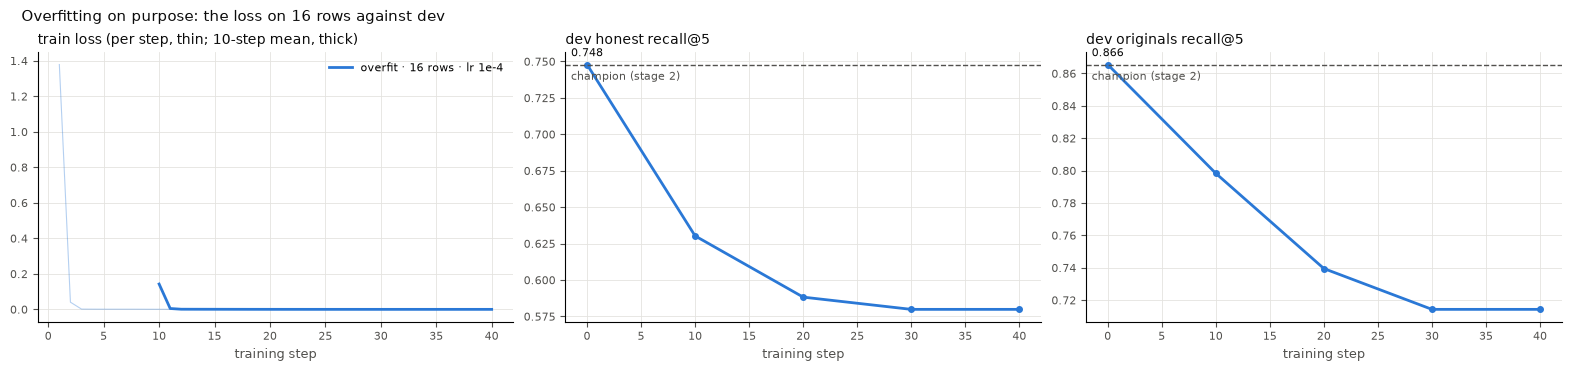

In [18]:
t0 = time.monotonic()
over = t.overfit_on_purpose(rows, n=16, lr=1e-4, epochs=40, eval_every=10, **TRAIN_ARGS, tags={"sweep": "overfit on purpose"},
                            description=describe("Overfitting on purpose: 16 rows, lr 1e-4, 40 steps.",
                                                 "To see what overfitting looks like: the train loss falls towards 0 while dev recall stops rising "
                                                 "and falls, so train loss alone proves nothing. Not a candidate.",
                                                 "16 original rows from 16 different lessons (one batch, the same batch every step), no warm-up, "
                                                 "dev scored every 10 steps."))
minutes["overfit"] = (time.monotonic() - t0) / 60
you.reveal("overfit_last_train_loss", over["losses"][-1]["train/loss"], as_percent=False)
you.reveal("overfit_last_dev_honest_recall", over["final"]["honest_recall_at_5"])
print(f"run {tracking.short(over['run_id'])}: {over['steps']} steps in {over['seconds_train'] / 60:.1f} min")
t.plot_runs({"overfit · 16 rows · lr 1e-4": over["run_id"]}, title="Overfitting on purpose: the loss on 16 rows against dev",
            lines={"held_out/honest_recall_at_5": ("champion (stage 2)", bar["honest.recall_at_5"]),
                   "held_out/originals_recall_at_5": ("champion (stage 2)", bar["originals.recall_at_5"])});

In [19]:
print(f"train loss: step 1 {over['losses'][0]['train/loss']:.3f} -> step {over['steps']} {over['losses'][-1]['train/loss']:.4f}")
for name in ("honest", "originals"):
    print(f"dev {name:9} recall@5: step 0 {over['step0'][f'{name}_recall_at_5']:.3f} -> best {over['best'][f'{name}_recall_at_5']:.3f} "
          f"(step {over['best_step']}) -> last {over['final'][f'{name}_recall_at_5']:.3f} "
          f"[{over['final'][f'{name}_recall_at_5_low']:.2f}, {over['final'][f'{name}_recall_at_5_high']:.2f}]")
last_vs_0 = over["paired"]["last_vs_step0"]
for name in ("honest", "originals"):
    p = last_vs_0[name]
    print(f"paired, step 0 against step {last_vs_0['step']} on the same {p['n']} dev {name} questions: {p['only_first']} found only at step 0, "
          f"{p['only_second']} only at the end; McNemar p {p['p_value']:.2g}; gap {p['gap_recall_at_5']:+.3f} [{p['gap_low']:+.3f}, {p['gap_high']:+.3f}]")
s0, fin = over["step0"], over["final"]
overlap = s0["honest_recall_at_5_low"] <= fin["honest_recall_at_5_high"]
print(f"(read separately, the honest Wilson ranges are [{s0['honest_recall_at_5_low']:.3f}, {s0['honest_recall_at_5_high']:.3f}] and "
      f"[{fin['honest_recall_at_5_low']:.3f}, {fin['honest_recall_at_5_high']:.3f}]: they {'overlap' if overlap else 'do not overlap'}. "
      "Two ranges are the wrong test for the same questions scored twice; the paired count above is the right one.)")
mlflow.log_metrics({f"overfit.last_vs_step0.{n}.p_value": last_vs_0[n]["p_value"] for n in ("honest", "originals")})

train loss: step 1 1.379 -> step 40 0.0001
dev honest    recall@5: step 0 0.748 -> best 0.748 (step 0) -> last 0.580 [0.49, 0.66]
dev originals recall@5: step 0 0.866 -> best 0.866 (step 0) -> last 0.714 [0.63, 0.79]
paired, step 0 against step 40 on the same 119 dev honest questions: 24 found only at step 0, 4 only at the end; McNemar p 0.00018; gap -0.168 [-0.252, -0.084]
paired, step 0 against step 40 on the same 119 dev originals questions: 21 found only at step 0, 3 only at the end; McNemar p 0.00028; gap -0.151 [-0.227, -0.076]
(read separately, the honest Wilson ranges are [0.663, 0.817] and [0.490, 0.665]: they overlap. Two ranges are the wrong test for the same questions scored twice; the paired count above is the right one.)


**Reading it.** The training loss fell from 1.38 to 0.0001: the model now picks the right paragraph for each of its 16
questions every time. On the dev questions it never saw, honest recall@5 fell from 0.748 to **0.580 [0.49, 0.66]** (20
fewer of 119 found) and originals from 0.866 to 0.714, most of it in the first 20 steps; the best checkpoint is step 0, the
untrained model.

Step 0 and step 40 score **the same 119 questions**, so the right test is a paired one (*Comparing on the same examples*):
24 questions were found only at step 0 and 4 only at the end, **McNemar p 0.0002**, and the paired bootstrap range of the
change is [−0.252, −0.084], all below zero. Both tests agree, so this fall is a **finding** from one run, not luck. Read
separately, the two Wilson ranges only just overlap ([0.663, 0.817] and [0.490, 0.665]), which would look like "maybe
luck": separate ranges ignore that most questions gave the same answer both times, so they are the wrong test here.

The lesson for every run below: **a falling train loss proves nothing on its own; only a held-out score can say whether the
skill improved.**

### Exercise 3: which number tells you the model learned the skill?

`"train loss"` or `"dev honest recall@5"`?

In [20]:
SKILL_NUMBER = "___"   # one of the two, as written

In [21]:
mine = attempt(SKILL_NUMBER, "SKILL_NUMBER")
if mine is not None:
    assert str(mine).strip().lower() == "dev honest recall@5", ("Not quite: the train loss is measured on the rows the model trains on, so it "
                                                                "can fall to zero while the model gets worse at everything else, as it just did.")
    print("Right: dev honest recall@5, scored on lessons the model never trained on, in a learner's words. The train loss only says the "
          "optimiser is doing its job on the rows it sees.")

Right: dev honest recall@5, scored on lessons the model never trained on, in a learner's words. The train loss only says the optimiser is doing its job on the rows it sees.


## 4. The learning rate (*Dev, test and holdout sets*)

> **In plain words.** The **learning rate** is how far each step moves the weights. Too small and three passes over the rows
> change little; too large and the model forgets what it knew before it learns the new thing (for a model this big, 1e-4
> is already large). Each run starts with a **warm-up** (the rate climbs from 0 over the first tenth of the steps, so the
> first, clumsiest steps are small) and then falls in a straight line to 0 by the last step.
>
> Three runs, everything else the same: learning rates **1e-5, 2e-5 and 5e-5**, seed 1101, 3 **epochs** (passes over all
> the rows), dev scored every 20 steps, checkpoints every 20 steps. The best checkpoint of each run is the one with the
> highest dev honest recall@5, and the winning rate is picked the same way.
>
> **Why dev and not test.** Picking is a look: the setting that came out best on a set is partly the one that got lucky on
> that set. Do the picking on dev, and test still measures the pick on questions nothing was chosen on. Pick on test, and
> there is no clean number left.

### Exercise 4: the warm-up, in steps

A run has 150 steps and warms up over the first 0.1 of them. For how many steps does the learning rate climb?

> **In plain words: a checkpoint.** A **checkpoint** is a saved copy of the model's weights at one step. Here the model is
> scored on dev every 20 steps, and its weights are kept only while that step is the run's best so far (the highest dev honest
> recall@5): when a later step beats it, the older copy's weights are deleted and only its scores stay, on disk and in MLflow.
> So each run ends with one kept copy, its **best checkpoint**, and the runs that are not picked lose that one too at the end of
> the notebook. LangGraph's checkpointer (*Human approval in LangGraph*) is the same idea for a graph: save where you got to.

In [22]:
WARMUP_STEPS = "___"   # a whole number

In [23]:
mine = attempt(WARMUP_STEPS, "WARMUP_STEPS")
if mine is not None:
    assert int(mine) == 15, "Not quite: a tenth of 150 steps. After those, the rate falls in a straight line to 0 at step 150."
    steps_here = -(-len(rows) // 16) * 3
    print(f"Right: 15. These runs have {len(rows)} rows, so {-(-len(rows) // 16)} steps per epoch and {steps_here} steps in 3 epochs: "
          f"a warm-up of {round(0.1 * steps_here)} steps.")

Right: 15. These runs have 825 rows, so 52 steps per epoch and 156 steps in 3 epochs: a warm-up of 16 steps.


> **In plain words: a sweep, and why its winner looks too good.** A setting chosen before training, like the learning rate, is a
> **hyperparameter** (the weights are what training learns). Running the same training with only that setting changed is a
> **sweep** (*Planning what to vary*). Picking the best of three on dev is the trap in *Testing many variants*: the real term for
> the optimism is **selection bias**, or the winner's curse, which is why the clean number is stage 4's.

**Your guess first.** Which learning rate gives the best dev honest recall@5: 1e-5, 2e-5 or 5e-5?

In [24]:
you.guess("lr_winner", None)   # e.g. 2e-5

No guess written down. The habit only works if you commit to one before you look.


In [25]:
LRS = (1e-5, 2e-5, 5e-5)
sweep = {}
minutes["lr_sweep"] = 0.0


def sweep_point(lr):
    # One learning rate: a child run, everything else the same as the other two. One cell per rate, so each fits the cell timeout.
    t0 = time.monotonic()
    sweep[f"lr {t.fmt_lr(lr)}"] = res = t.train(
        rows, lr=lr, epochs=3, batch=16, seed=t.SEED, eval_every=20, save_every=20, **TRAIN_ARGS, tags={"sweep": "learning_rate"},
        description=describe(f"Learning-rate sweep: lr {t.fmt_lr(lr)}, seed {t.SEED}, 3 epochs.",
                             "One of three runs that differ only in the learning rate (1e-5, 2e-5, 5e-5), to pick the rate on dev honest "
                             "recall@5 before a second seed and stage 4's test."))
    minutes["lr_sweep"] += (time.monotonic() - t0) / 60
    print(f"{res['run_name']} ({tracking.short(res['run_id'])}): {res['steps']} steps in {res['seconds_train'] / 60:.1f} min, "
          f"{res['seconds_per_step']:.2f} s/step (gradient checkpointing {res['params']['gradient_checkpointing']}); best step {res['best_step']}, "
          f"dev honest {res['best']['honest_recall_at_5']:.3f}, originals {res['best']['originals_recall_at_5']:.3f}")

In [26]:
sweep_point(1e-5)

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


  step    0 · dev honest recall@5 0.748 · originals recall@5 0.866 · eval 11 s


  step   20 · dev honest recall@5 0.790 · originals recall@5 0.908 · eval 12 s


  step   40 · dev honest recall@5 0.773 · originals recall@5 0.933 · eval 12 s


  step   60 · dev honest recall@5 0.807 · originals recall@5 0.941 · eval 12 s


  step   80 · dev honest recall@5 0.832 · originals recall@5 0.933 · eval 12 s


  step  100 · dev honest recall@5 0.815 · originals recall@5 0.924 · eval 12 s


  step  120 · dev honest recall@5 0.790 · originals recall@5 0.924 · eval 12 s


  step  140 · dev honest recall@5 0.798 · originals recall@5 0.924 · eval 12 s


  step  156 · dev honest recall@5 0.798 · originals recall@5 0.924 · eval 12 s


train · bge-large · full · lr 1e-5 · seed 1101 (a8ebc15d): 156 steps in 7.6 min, 2.01 s/step (gradient checkpointing True); best step 80, dev honest 0.832, originals 0.933


In [27]:
sweep_point(2e-5)

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


  step    0 · dev honest recall@5 0.748 · originals recall@5 0.866 · eval 12 s


  step   20 · dev honest recall@5 0.798 · originals recall@5 0.933 · eval 12 s


  step   40 · dev honest recall@5 0.815 · originals recall@5 0.933 · eval 12 s


  step   60 · dev honest recall@5 0.807 · originals recall@5 0.941 · eval 12 s


  step   80 · dev honest recall@5 0.815 · originals recall@5 0.924 · eval 12 s


  step  100 · dev honest recall@5 0.798 · originals recall@5 0.916 · eval 12 s


  step  120 · dev honest recall@5 0.790 · originals recall@5 0.916 · eval 12 s


  step  140 · dev honest recall@5 0.790 · originals recall@5 0.916 · eval 12 s


  step  156 · dev honest recall@5 0.782 · originals recall@5 0.908 · eval 12 s


train · bge-large · full · lr 2e-5 · seed 1101 (9a8be692): 156 steps in 7.6 min, 2.05 s/step (gradient checkpointing True); best step 40, dev honest 0.815, originals 0.933


In [28]:
sweep_point(5e-5)

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


  step    0 · dev honest recall@5 0.748 · originals recall@5 0.866 · eval 12 s


  step   20 · dev honest recall@5 0.815 · originals recall@5 0.924 · eval 12 s


  step   40 · dev honest recall@5 0.790 · originals recall@5 0.916 · eval 12 s


  step   60 · dev honest recall@5 0.782 · originals recall@5 0.908 · eval 12 s


  step   80 · dev honest recall@5 0.832 · originals recall@5 0.882 · eval 12 s


  step  100 · dev honest recall@5 0.756 · originals recall@5 0.882 · eval 12 s


  step  120 · dev honest recall@5 0.748 · originals recall@5 0.882 · eval 12 s


  step  140 · dev honest recall@5 0.765 · originals recall@5 0.891 · eval 12 s


  step  156 · dev honest recall@5 0.773 · originals recall@5 0.882 · eval 12 s


train · bge-large · full · lr 5e-5 · seed 1101 (9c7a54fc): 156 steps in 7.6 min, 2.02 s/step (gradient checkpointing True); best step 80, dev honest 0.832, originals 0.882


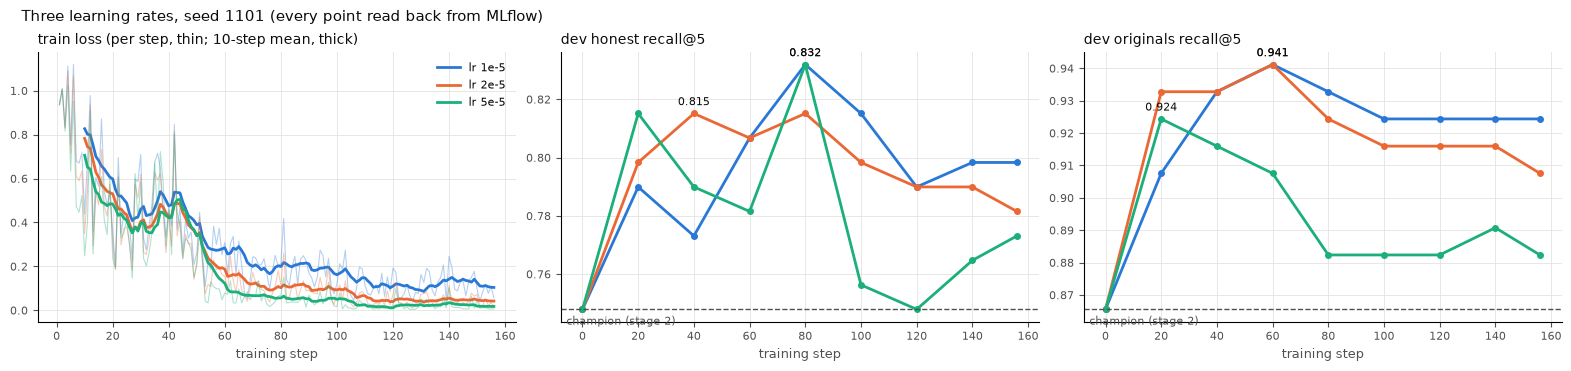

,steps,best step,honest step 0,honest best,honest best range,honest last,originals step 0,originals best,originals last,honest hit@1 best,s/step,minutes,peak GB,checkpointing
run,,,,,,,,,,,,,,
lr 1e-5,156,80,0.748,0.832,"[0.75, 0.89]",0.798,0.866,0.933,0.924,0.546,2.01,7.6,12.6,True
lr 2e-5,156,40,0.748,0.815,"[0.74, 0.87]",0.782,0.866,0.933,0.908,0.538,2.05,7.6,12.6,True
lr 5e-5,156,80,0.748,0.832,"[0.75, 0.89]",0.773,0.866,0.882,0.882,0.479,2.02,7.6,13.6,True


In [29]:
t.plot_runs({name: res["run_id"] for name, res in sweep.items()}, title="Three learning rates, seed 1101 (every point read back from MLflow)",
            lines={"held_out/honest_recall_at_5": ("champion (stage 2)", bar["honest.recall_at_5"]),
                   "held_out/originals_recall_at_5": ("champion (stage 2)", bar["originals.recall_at_5"])});
sweep_table = t.runs_table(sweep)
mlflow.log_table(sweep_table.reset_index(), "tables/lr_sweep.json")
sweep_table.round(3)

In [30]:
chosen = t.pick_best(sweep)   # highest dev honest recall@5 at its best step, then originals, then the earlier run
chosen_lr = sweep[chosen]["params"]["learning_rate"] if chosen else 2e-5
you.reveal("lr_winner", chosen_lr, as_percent=False)
honest_best = {name: res["best"]["honest_recall_at_5"] for name, res in sweep.items()}
spread = max(honest_best.values()) - min(honest_best.values())
mlflow.log_params({"chosen_lr": chosen_lr, "chosen_lr.why": "highest dev honest recall@5 at its best step (tie: originals, then the earlier run)"})
mlflow.log_metric("lr_sweep.spread_best_honest", spread)
print(f"picked: {chosen} (best dev honest recall@5 {honest_best.get(chosen, float('nan')):.3f} at step {sweep[chosen]['best_step'] if chosen else '-'})."
      f" The three runs' best honest scores span {spread:.3f}, which is {round(spread * len(honest_dev))} of {len(honest_dev)} questions.")

lr_winner: it was 1e-05 (no guess written down)
picked: lr 1e-5 (best dev honest recall@5 0.832 at step 80). The three runs' best honest scores span 0.017, which is 2 of 119 questions.


**Reading it.** All three rates beat their own step 0 on dev honest, at their best checkpoint (0.832, 0.815 and 0.832
against 0.748) and at their **last** step too (0.798, 0.782, 0.773). The last step was not chosen on dev, so that part is
not checkpoint-picking luck, though it can still be ordinary luck (section 5): paired against step 0 on the same
questions, no run's last step clears McNemar at 0.05 (p from 0.26 to 0.68, logged as `paired.last_vs_step0.honest.p_value`).
On originals all three went *up* (0.866 to between 0.88 and 0.93 at the best checkpoint, 0.88 to 0.92 at the last step):
no sign of forgetting.

Which rate wins is **not shown**. 1e-5 and 5e-5 tie at 0.832 on dev honest and 2e-5 is 2 questions behind (0.815), out of
119, each with a Wilson range about 13 points wide. 1e-5 is picked because the rule says "highest dev honest recall@5, then
originals": the tie goes to 1e-5 on originals (0.933 against 0.882). That is a tie-break, not a finding. **This pass picked
a different rate from the 86-rewrite pass**, which picked 2e-5 by 2 questions: with 279 more rows, the order of three
near-equal rates changed, which is what happens when a tie-break decides. The shapes are the useful part. 5e-5 jumps early
(0.815 at step 20), wobbles, touches 0.832 at step 80 and falls back to 0.75 to 0.77, and it is the one rate that gives
back most of its gain on originals (0.882 at its best): a high rate learning fast and then overshooting. 1e-5 climbs to step
80 and eases off; 2e-5 peaks at step 40 and eases off. Hunch: on test, 1e-5 and 2e-5 would do about as well, and 5e-5 is
the riskiest.

Why dev and not test, once more: four runs in this pass (the overfit run and three rates), and every run of the earlier
passes, have now been scored on these 119 questions, and the best of three rates is the best partly by luck. Test has not
been looked at, so it can still say how good the pick really is.

## 5. Seeds: how much is luck? (*Telling real gains from noise*, *Margins near 0% and 100%*)

> **In plain words.** A **seed** fixes the random choices of a run: the order the rows are dealt into batches, the dropout
> (the random switching-off of some numbers during training). Change only the seed and the result moves a little, by luck
> alone. That movement is **seed-to-seed variation** (also called run-to-run variance): a difference between two settings
> smaller than the difference between two seeds of one setting is not a finding. Two seeds give one such difference, which
> is a rough measure of it, not a measured spread.
> And it is read at the **last** steps, which dev did not pick, beside the biggest move between neighbouring checkpoints
> of one run: each run's *best* checkpoint is the top of a wobbly line, so two bests sit closer together than luck does.
>
> The second run uses the chosen learning rate and seed 1102. Each run's best dev honest recall@5 is shown with its
> **Wilson range** (the range where the true share plausibly sits, given how many questions there are).

**Your guess first.** How far apart will the two seeds' best dev honest recall@5 be (e.g. 0.01 is about one question)?

> **In plain words: seed-to-seed variation, evaluation mode and the GPU.** **Seed-to-seed variation** is how far a score
> moves when nothing but the seed changes; *Telling real gains from noise* teaches the habit of several seeds per setup.
> **Dropout** is on only while training: when the model is measured it is put in **evaluation mode**, with dropout off, so a
> score does not wobble. Even the same seed can give slightly different numbers on a GPU, because some of its sums may add
> the numbers in a different order from run to run, and each order rounds a little differently.

In [31]:
you.guess("seed_gap_honest", None)   # e.g. 0.02

No guess written down. The habit only works if you commit to one before you look.


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


  step    0 · dev honest recall@5 0.748 · originals recall@5 0.866 · eval 11 s


  step   20 · dev honest recall@5 0.748 · originals recall@5 0.899 · eval 12 s


  step   40 · dev honest recall@5 0.815 · originals recall@5 0.916 · eval 12 s


  step   60 · dev honest recall@5 0.807 · originals recall@5 0.916 · eval 12 s


  step   80 · dev honest recall@5 0.790 · originals recall@5 0.933 · eval 12 s


  step  100 · dev honest recall@5 0.798 · originals recall@5 0.933 · eval 12 s


  step  120 · dev honest recall@5 0.765 · originals recall@5 0.933 · eval 12 s


  step  140 · dev honest recall@5 0.756 · originals recall@5 0.933 · eval 12 s


  step  156 · dev honest recall@5 0.756 · originals recall@5 0.933 · eval 12 s


seed_gap_honest: it was 0.0168 (no guess written down)


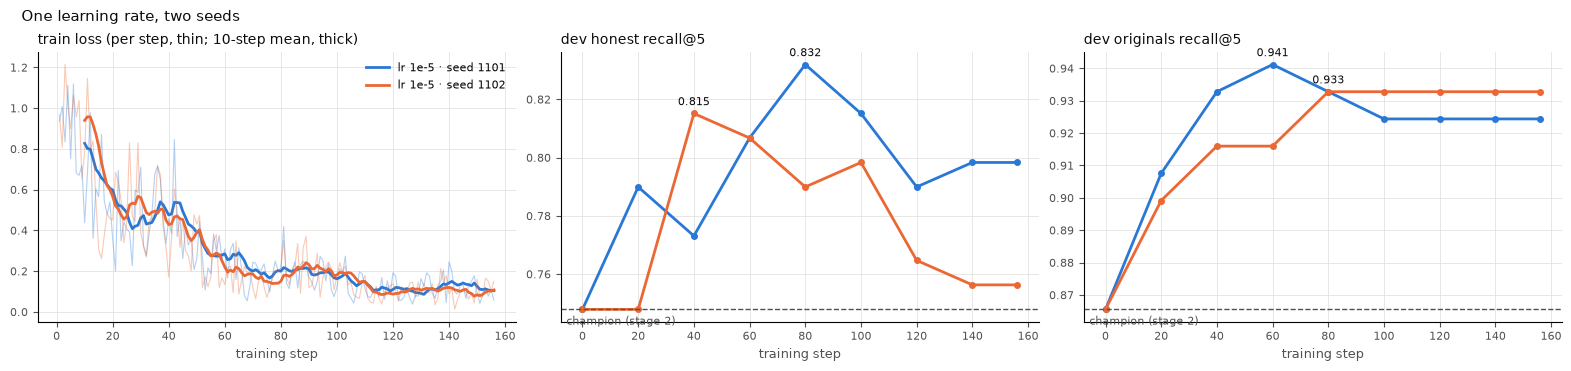

,steps,best step,honest step 0,honest best,honest best range,honest last,originals step 0,originals best,originals last,honest hit@1 best,s/step,minutes,peak GB,checkpointing
run,,,,,,,,,,,,,,
lr 1e-5 · seed 1101,156,80,0.748,0.832,"[0.75, 0.89]",0.798,0.866,0.933,0.924,0.546,2.01,7.6,12.6,True
lr 1e-5 · seed 1102,156,40,0.748,0.815,"[0.74, 0.87]",0.756,0.866,0.916,0.933,0.571,1.99,7.5,13.6,True


In [32]:
t0 = time.monotonic()
SEED2 = t.SEED + 1
second = t.train(rows, lr=chosen_lr, epochs=3, batch=16, seed=SEED2, eval_every=20, save_every=20, **TRAIN_ARGS, tags={"sweep": "seed"},
                 description=describe(f"Second seed of the chosen learning rate: lr {t.fmt_lr(chosen_lr)}, seed {SEED2}, 3 epochs.",
                                      "The same run as the chosen sweep point with only the seed changed, so the gap between the two (read at "
                                      "the last steps, which dev did not pick) and the moves between neighbouring checkpoints of each run "
                                      "give the seed-to-seed variation on dev: a difference smaller than it is not a finding."))
minutes["seed"] = (time.monotonic() - t0) / 60
seeds = {f"lr {t.fmt_lr(chosen_lr)} · seed {t.SEED}": sweep[chosen], f"lr {t.fmt_lr(chosen_lr)} · seed {SEED2}": second}
seed_table = t.runs_table(seeds)
mlflow.log_table(seed_table.reset_index(), "tables/seeds.json")
gap_seeds = abs(sweep[chosen]["best"]["honest_recall_at_5"] - second["best"]["honest_recall_at_5"])
gap_seeds_orig = abs(sweep[chosen]["best"]["originals_recall_at_5"] - second["best"]["originals_recall_at_5"])
mlflow.log_metrics({"seeds.gap_best_honest": gap_seeds, "seeds.gap_best_originals": gap_seeds_orig})
you.reveal("seed_gap_honest", gap_seeds, as_percent=False)
t.plot_runs({name: res["run_id"] for name, res in seeds.items()}, title="One learning rate, two seeds",
            lines={"held_out/honest_recall_at_5": ("champion (stage 2)", bar["honest.recall_at_5"]),
                   "held_out/originals_recall_at_5": ("champion (stage 2)", bar["originals.recall_at_5"])});
seed_table.round(3)

In [33]:
n = len(honest_dev)


def biggest_move(res, name):
    # The biggest change of dev recall@5 between neighbouring checkpoints after step 0 (the first move is the training itself).
    ys = [c[f"{name}_recall_at_5"] for c in res["curve"][1:]]
    return max((abs(b - a) for a, b in zip(ys, ys[1:])), default=0.0)


gap_last = abs(sweep[chosen]["final"]["honest_recall_at_5"] - second["final"]["honest_recall_at_5"])
move = max(biggest_move(res, "honest") for res in seeds.values())
floor = max(gap_last, move)
mlflow.log_metrics({"seeds.gap_last_honest": gap_last, "seeds.biggest_checkpoint_move_honest": move, "seeds.luck_floor_honest": floor})
print(f"the two seeds' best checkpoints are {gap_seeds:.3f} apart on honest ({round(gap_seeds * n)} of {n} questions), {gap_seeds_orig:.3f} on originals; "
      "each best is the top of a wobbly line, so that is not the seed-to-seed variation")
print(f"seed-to-seed variation on dev honest: {floor:.3f} ({round(floor * n)} of {n} questions), the larger of the two seeds' last steps apart "
      f"({gap_last:.3f}, {round(gap_last * n)} of {n}) and the biggest move between neighbouring checkpoints after step 0 in either run "
      f"({move:.3f}, {round(move * n)} of {n})")
print(f"the learning rates' best honest scores spanned {spread:.3f} ({round(spread * n)} of {n} questions): "
      + ("wider than the seed-to-seed variation, a lead that the rate matters, from one seed per rate." if spread > floor
         else "not wider than the seed-to-seed variation, so it is not shown that the rate matters; the pick is a tie-break, not a finding."))
for name, res in seeds.items():
    b = res["best"]
    print(f"  {name}: best honest {b['honest_recall_at_5']:.3f} [{b['honest_recall_at_5_low']:.2f}, {b['honest_recall_at_5_high']:.2f}], "
          f"last {res['final']['honest_recall_at_5']:.3f}; gain over its own step 0 {b['honest_recall_at_5'] - res['step0']['honest_recall_at_5']:+.3f} "
          f"at the best, {res['final']['honest_recall_at_5'] - res['step0']['honest_recall_at_5']:+.3f} at the last step")


the two seeds' best checkpoints are 0.017 apart on honest (2 of 119 questions), 0.017 on originals; each best is the top of a wobbly line, so that is not the seed-to-seed variation
seed-to-seed variation on dev honest: 0.067 (8 of 119 questions), the larger of the two seeds' last steps apart (0.042, 5 of 119) and the biggest move between neighbouring checkpoints after step 0 in either run (0.067, 8 of 119)
the learning rates' best honest scores spanned 0.017 (2 of 119 questions): not wider than the seed-to-seed variation, so it is not shown that the rate matters; the pick is a tie-break, not a finding.
  lr 1e-5 · seed 1101: best honest 0.832 [0.75, 0.89], last 0.798; gain over its own step 0 +0.084 at the best, +0.050 at the last step
  lr 1e-5 · seed 1102: best honest 0.815 [0.74, 0.87], last 0.756; gain over its own step 0 +0.067 at the best, +0.008 at the last step


**Reading it.** The two seeds' best checkpoints are 2 questions apart (0.832 and 0.815), but each best is the top of a
wobbly line, so that gap says little about luck. The printed seed-to-seed variation reads it two better ways:

* the two seeds' **last** steps are 0.798 and 0.756, 5 questions apart;
* *within* one run, dev honest moves by up to 8 questions between neighbouring checkpoints (seed 1102: 0.748 at step 20,
  0.815 at step 40).

So the seed-to-seed variation on this dev set is about 8 questions, and the learning rates' 2-question spread sits well
inside it: which rate is best is not shown. What holds across both seeds is the direction at the best checkpoint: +0.084
and +0.067. At the **last** step it is weaker than in the 86-rewrite pass: +0.050 and +0.008 (6 questions and 1), because
seed 1102 drifts down from step 40 to the end (0.815 to 0.756) while its originals hold at 0.933. Hunch, from one seed:
three epochs over 825 rows is more training than this rate needs on learner wording, and the best checkpoint matters more
now than it did with 546 rows.


### Exercise 5: is it a finding?

Setting A beats setting B by 0.02 on dev honest recall@5. Two seeds of setting A differ by 0.04. Is A's win a finding:
`"yes"` or `"no"`?

In [34]:
SEED_READING = "___"   # "yes" or "no"

In [35]:
mine = attempt(SEED_READING, "SEED_READING")
if mine is not None:
    assert str(mine).strip().lower() == "no", "Not quite: changing nothing but the seed moved A by 0.04, so a 0.02 win is inside what luck alone does."
    print("Right: no. A 0.02 win is half of what luck moved the same setting. Say 'not shown', and more seeds (or more questions) "
          "are what would settle it.")

Right: no. A 0.02 win is half of what luck moved the same setting. Say 'not shown', and more seeds (or more questions) are what would settle it.


> **In plain words: logging a model.** A run's artifacts are just files. A **logged model** is the model saved with how to load it
> (its **flavour**, here `sentence_transformers`) and a **signature**: what goes in (a list of texts) and what comes out (one vector
> per text). The **input example** is one real input saved beside it, so whoever serves the model later can test the call. Only a
> logged model can be registered and given an alias (*Model registry and promotion*).

**The candidate for stage 4.** Of every full fine-tune above (three learning rates and the second seed), the one whose best
checkpoint scored highest on dev honest recall@5 (originals as the tie-break) is the candidate. Only its model is logged
to MLflow (`mlflow.sentence_transformers.log_model`, with a signature and an input example: 1.3 GB, so once, not per run),
and it is tagged `candidate=stage4`. The other runs keep their scores in MLflow; their kept weights on disk are trimmed at
the end of the notebook.

In [36]:
full_runs = {**sweep, f"lr {t.fmt_lr(chosen_lr)} · seed {SEED2}": second}
best_name = t.pick_best(full_runs)
if best_name is None:
    candidate = None
    print("No full run beat its own step 0 on dev honest recall@5: there is no trained candidate, and nothing is logged as a model.")
else:
    candidate = full_runs[best_name]
    t0 = time.monotonic()
    t.log_candidate_model(candidate, tags={"candidate": "stage4", "candidate.why": "highest dev honest recall@5 of the full fine-tunes in 03_train"})
    minutes["log_model"] = (time.monotonic() - t0) / 60
    mlflow.set_tags({"candidate_run": tracking.short(candidate["run_id"]), "candidate_name": candidate["run_name"]})
    print(f"candidate: {candidate['run_name']} (run {tracking.short(candidate['run_id'])}), best step {candidate['best_step']}, "
          f"dev honest {candidate['best']['honest_recall_at_5']:.3f}, originals {candidate['best']['originals_recall_at_5']:.3f}; "
          f"model logged in {60 * minutes['log_model']:.0f} s")

2026/11/08 19:03:53 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/huydo/Developer/dd-retrieval/notebooks/learning/coach_retrieval


2026/11/08 19:03:54 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/huydo/Developer/dd-retrieval/notebooks/learning/coach_retrieval


2026/11/08 19:03:54 INFO mlflow.utils.environment: Detected uv project at /Users/huydo/Developer/dd-retrieval/notebooks/learning/coach_retrieval. Attempting to export requirements via 'uv export'.


2026/11/08 19:03:54 INFO mlflow.utils.uv_utils: Exported 258 dependencies via uv


2026/11/08 19:03:54 INFO mlflow.utils.environment: Successfully exported 258 requirements from uv project. Skipping package capture based inference.


2026/11/08 19:03:55 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


candidate: train · bge-large · full · lr 1e-5 · seed 1101 (run a8ebc15d), best step 80, dev honest 0.832, originals 0.933; model logged in 4 s


## 6. The size trade-off: LoRA (*The cost of embeddings*)

> **In plain words.** A full fine-tune changes all 335 million weights, so every fine-tuned copy is another 1.3 GB to store
> and serve. **LoRA** (low-rank adaptation) freezes them and trains small add-on matrices beside the attention layers'
> query and value parts instead: about half a percent as many numbers, saved as an **adapter** of a few MB that is loaded on
> top of the shipped model. If it scores as well, one base model could serve several adapters. The smoke run showed LoRA
> works through the same code.
>
> **One change from the plan, said plainly:** the LoRA run uses learning rate **1e-4**, not the chosen full-fine-tune rate.
> The adapters start at zero and are small, so at the full model's rate they barely move in three epochs; a rate several
> times higher is the usual starting point for LoRA. So this compares *LoRA at a usual LoRA rate* with *the full fine-tune
> at its picked rate*, one seed each: a first look at the size trade-off, not a tuned LoRA.

> **In plain words: the LoRA words.** A **matrix** is a table of numbers, and most of a model is such tables. The **attention
> layers** are the parts that decide which words in a text to weigh together; **query** and **value** are two of their tables.
> **Low-rank** means the add-on is two thin tables multiplied together (r16: the thin side of each is 16 numbers), far fewer numbers than the table it
> adjusts; alpha 32 sets how strongly it counts, and dropout 0.1 switches off a tenth of what goes into the add-on, at random, while training.
> **Under-trained** means training stopped before the model had learned what it could; the sign here is that the dev curve
> was still edging up at the end.

In [37]:
t0 = time.monotonic()
LORA_LR = 1e-4
lora = t.train(rows, lr=LORA_LR, epochs=3, batch=16, seed=t.SEED, eval_every=20, save_every=20, lora=t.LORA_DEFAULT, **TRAIN_ARGS,
               tags={"sweep": "lora"}, log_model=True,
               description=describe(f"LoRA r{t.LORA_DEFAULT['r']} at lr {t.fmt_lr(LORA_LR)}, seed {t.SEED}, 3 epochs.",
                                    "The size trade-off: small adapter matrices (a few MB) instead of a 1.3 GB full copy. Its best checkpoint's "
                                    "adapter is logged as an artifact (not a full model).",
                                    f"LoRA {t.LORA_DEFAULT} on the attention's query and value layers; the base weights frozen; lr 1e-4 because "
                                    "adapters start at zero and need a higher rate than a full fine-tune."))
minutes["lora"] = (time.monotonic() - t0) / 60
pair = ({"full · " + candidate["run_name"]: candidate} if candidate else {}) | {"lora · " + lora["run_name"]: lora}
size_rows = [{"run": name, "trains": f"{res['counts']['params_trainable']:,} numbers ({res['counts']['trainable_share']:.2%})",
              "stored MB": res["adapter_mb"] if res["adapter_mb"] else t.folder_mb(res["best_dir"]),
              "dev honest best": res["best"]["honest_recall_at_5"],
              "honest range": f"[{res['best']['honest_recall_at_5_low']:.2f}, {res['best']['honest_recall_at_5_high']:.2f}]",
              "dev originals best": res["best"]["originals_recall_at_5"], "best step": res["best_step"], "s/step": round(res["seconds_per_step"], 2)}
             for name, res in pair.items()]
size_table = pd.DataFrame(size_rows).set_index("run")
mlflow.log_table(size_table.reset_index(), "tables/lora_vs_full.json")
mlflow.log_metrics({"lora.adapter_mb": lora["adapter_mb"] or 0.0, "lora.best_honest": lora["best"]["honest_recall_at_5"],
                    "lora.best_originals": lora["best"]["originals_recall_at_5"]})
size_table.round(3)

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


  step    0 · dev honest recall@5 0.748 · originals recall@5 0.866 · eval 12 s


  step   20 · dev honest recall@5 0.773 · originals recall@5 0.866 · eval 12 s


/Users/huydo/Developer/dd-retrieval/notebooks/learning/coach_retrieval/.venv/lib/python3.13/site-packages/peft/utils/save_and_load.py:313: UserWarning: Could not find a config file in BAAI/bge-large-en-v1.5 - will assume that the vocabulary was not modified.
  warnings.warn(


  step   40 · dev honest recall@5 0.739 · originals recall@5 0.899 · eval 12 s


  step   60 · dev honest recall@5 0.765 · originals recall@5 0.916 · eval 12 s


... (2 outputs left out)

  step  120 · dev honest recall@5 0.798 · originals recall@5 0.908 · eval 12 s


  step  140 · dev honest recall@5 0.790 · originals recall@5 0.908 · eval 12 s


  step  156 · dev honest recall@5 0.790 · originals recall@5 0.908 · eval 12 s


,trains,stored MB,dev honest best,honest range,dev originals best,best step,s/step
run,,,,,,,
full · train · bge-large · full · lr 1e-5 · seed 1101,"335,141,888 numbers (100.00%)",1341.35,0.832,"[0.75, 0.89]",0.933,80,2.01
lora · train · bge-large · lora r16 · lr 1e-4 · seed 1101,"1,572,864 numbers (0.47%)",6.30,0.798,"[0.72, 0.86]",0.908,120,1.65


**Reading it.** The adapter is **6.3 MB against 1,341 MB** for the full copy (about 210 times smaller). It trains 0.47% of
the numbers and takes 1.65 s a step against 2.01. On dev honest it reached 0.798 [0.72, 0.86] at step 120, 6 questions
above the untrained model and 4 below the full fine-tune (paired against its own step 0, McNemar p 0.15: not shown). In the
86-rewrite pass it reached 0.773, 6 below the full fine-tune then. On originals it reached 0.908 at that step (0.941 at
steps 80 and 100). Its curve dipped at step 40 (0.739) and was still near its top at the end. Hunch: it is still
under-trained, because three epochs at 1e-4 is a first guess, not a tuned LoRA. On this run, the full fine-tune gained more
on learner wording. That is one seed each, so it is not shown in general.

The size win matters most on Databricks: one served base model with several small adapters, instead of a 1.3 GB copy per
fine-tune. Stage 8 can revisit LoRA with a longer run and its own sweep of learning rates.

## 7. Against the champion, on dev (*Comparing on the same examples*, *Embedding models have blind spots*)

This is **not the bar**. The bar is stage 4's: the candidate against the champion on the **test** lessons, measured once.
Here the candidate's best checkpoint is loaded from disk and scored by the same code that scored every baseline in stage 2
(`retrieval.evaluate_setup`), beside the champion, on the same dev questions, so the two are compared **pair by pair**:

* on **dev honest** (learner wording): did it find more of the questions only one of the two found?
* on **dev originals** (the course's wording, the same questions): the **forgetting check**, did it lose questions the
  champion found? A fine-tune can buy a gain on new wording by losing old wording, and only a paired count shows that.

**Your guess first.** By how much will the candidate beat the champion on dev honest recall@5 (negative if it loses)?

> **In plain words: forgetting.** When a fine-tune gets better at the new job and worse at what it could already do, the real term
> is **catastrophic forgetting**. The check is the regression count from *Reading regressions and improvements*: on the course's
> own wording, count the questions the champion found that the candidate now misses, pair by pair.

In [38]:
you.guess("candidate_gap_honest", None)   # e.g. 0.05

No guess written down. The habit only works if you commit to one before you look.


In [39]:
t0 = time.monotonic()
assert candidate is not None, "No candidate (see section 5): nothing to compare, and nothing for stage 4."
CANDIDATE = r.Setup(f"bge-large · fine-tuned · {candidate['run_name'].removeprefix('train · bge-large · ')}", "local", candidate["best_dir"], r.BGE_QUERY)
t.release_champion()
champ = r.evaluate_setup(r.CHAMPION, corpus, dev_sets, splits)
cand = r.evaluate_setup(CANDIDATE, corpus, dev_sets, splits)
vs = {name: t.versus(champ["sets"][name]["rows"], cand["sets"][name]["rows"]) for name in dev_sets}
same_as_run = abs(cand["sets"]["honest"]["summary"]["recall_at_5"] - candidate["best"]["honest_recall_at_5"])
vs_table = pd.DataFrame([{"set": name, "n": vs[name]["n"],
                          "champion recall@5": champ["sets"][name]["summary"]["recall_at_5"], "candidate recall@5": cand["sets"][name]["summary"]["recall_at_5"],
                          "only champion found": vs[name]["only_first"], "only candidate found": vs[name]["only_second"],
                          "McNemar p": vs[name]["p_value"], "gap": vs[name]["gap_recall_at_5"], "gap low": vs[name]["gap_low"],
                          "gap high": vs[name]["gap_high"], "reading (the bar: both tests)": vs[name]["reading"],
                          "range reading": vs[name]["range_reading"],
                          "champion hit@1": champ["sets"][name]["summary"]["hit_at_1"], "candidate hit@1": cand["sets"][name]["summary"]["hit_at_1"]}
                         for name in dev_sets]).set_index("set")
mlflow.log_table(vs_table.reset_index(), "tables/candidate_vs_champion_dev.json")
mlflow.log_metrics({f"vs_champion.{name}.{k}": float(vs[name][k]) for name in dev_sets
                    for k in ("gap_recall_at_5", "gap_low", "gap_high", "p_value", "only_first", "only_second")})
you.reveal("candidate_gap_honest", vs["honest"]["gap_recall_at_5"], as_percent=False)
print(f"check: the candidate scored here {cand['sets']['honest']['summary']['recall_at_5']:.3f} on honest, its run logged "
      f"{candidate['best']['honest_recall_at_5']:.3f} at step {candidate['best_step']} (difference {same_as_run:.3f}: the same model, scored the same way)")
print(f"check: step 0 of that run is the champion: honest hit@1 {candidate['step0']['honest_hit_at_1']:.3f} at step 0 (scored at "
      f"{candidate['params']['max_seq_length.scored_and_saved']} tokens), {champ['sets']['honest']['summary']['hit_at_1']:.3f} for the champion")
print(f"'reading' is stage 2's bar: the paired bootstrap range above zero AND McNemar p under {t.P_BAR}; 'range reading' is the range alone")
vs_table.round(3)

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-large-en-v1.5: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-large-en-v1.5'.


bge-large · local · with prompt          corpus    9.7 s · honest recall@5 0.75 · originals recall@5 0.87 · 12 s in all


bge-large · fine-tuned · full · lr 1e-5 · seed 1101 corpus    9.9 s · honest recall@5 0.83 · originals recall@5 0.93 · 12 s in all
candidate_gap_honest: it was 0.084 (no guess written down)
check: the candidate scored here 0.832 on honest, its run logged 0.832 at step 80 (difference 0.000: the same model, scored the same way)
check: step 0 of that run is the champion: honest hit@1 0.487 at step 0 (scored at 512 tokens), 0.487 for the champion
'reading' is stage 2's bar: the paired bootstrap range above zero AND McNemar p under 0.05; 'range reading' is the range alone


,n,champion recall@5,candidate recall@5,only champion found,only candidate found,McNemar p,gap,gap low,gap high,reading (the bar: both tests),range reading,champion hit@1,candidate hit@1
set,,,,,,,,,,,,,
honest,119,0.748,0.832,5,15,0.041,0.084,0.017,0.160,candidate better,candidate better,0.487,0.546
originals,119,0.866,0.933,1,9,0.021,0.067,0.017,0.118,candidate better,candidate better,0.706,0.765


**The weakest module, before and after.** Only modules with at least five dev questions are read (a module with one
question scores 0 or 1 by chance). Stage 2 named `security` the champion's weak spot: weakest on the course wording, and next to `production` on the
learner wording (2 of 5 against 2 of 6).

In [40]:
for name in dev_sets:
    print(f"{name:9} champion's weakest (5+ questions): {t.weakest(champ['sets'][name]['summary'])}")
    print(f"{'':9} candidate's weakest (5+ questions): {t.weakest(cand['sets'][name]['summary'])}")
by_mod = {m["module"]: m for m in cand["sets"]["honest"]["summary"]["by_module"]}
moved = sorted(((m["module"], m["found"], by_mod[m["module"]]["found"], m["n"]) for m in champ["sets"]["honest"]["summary"]["by_module"]
                if m["n"] >= 5), key=lambda x: x[2] - x[1])
print("honest, modules with 5+ questions, champion -> candidate found:", ", ".join(f"{m} {a}->{b}/{n}" for m, a, b, n in moved))
mlflow.set_tags({"weakest_5plus.honest.champion": (t.weakest(champ["sets"]["honest"]["summary"]) or ["-"])[0],
                 "weakest_5plus.honest.candidate": (t.weakest(cand["sets"]["honest"]["summary"]) or ["-"])[0]})

honest    champion's weakest (5+ questions): ['production 2/6', 'security 2/5', 'rag 4/8']
          candidate's weakest (5+ questions): ['experiments 5/9', 'rag 5/8', 'production 4/6']
originals champion's weakest (5+ questions): ['security 2/5', 'production 4/6', 'terraform 5/6']
          candidate's weakest (5+ questions): ['production 5/6', 'rag 7/8', 'agents 8/9']
honest, modules with 5+ questions, champion -> candidate found: agents 9->7/9, evals 14->13/14, experiments 5->5/9, rag 4->5/8, terraform 5->6/6, pricing 8->9/9, production 2->4/6, security 2->4/5


**Speed and cost.** Speed is measured the way stage 2 measured the bar's speed line: five passes over the same 119
course-worded questions, batch 32, model load off the clock, champion and candidate in the same session, so the medians can
be compared and the spread says what counts as noise. A full fine-tune is the same model shape as the champion, so it should
be the same speed and the same size; this checks it. The dollar line is 0 here by construction; stage 8 adds Databricks'
prices, where the champion is a pay-per-token endpoint with no upkeep and a fine-tune is a served model paid by the hour.

In [41]:
questions = [p["question"] for p in originals_dev]
speed = {s.name: r.speed_passes(s, questions, passes=5) for s in (r.CHAMPION, CANDIDATE)}
cost = pd.DataFrame([{"setup": name, "ms/question median": sp["ms_per_question_median"], "spread ms": sp["ms_spread"],
                      "model MB": r.model_size_mb(r.CHAMPION) if name == r.CHAMPION.name else t.folder_mb(candidate["best_dir"]),
                      "usd here": 0.0, "usd on Databricks": "stage 8"} for name, sp in speed.items()]).set_index("setup")
mlflow.log_dict(speed, "speed_passes_dev.json")
mlflow.log_metrics({"speed.champion.ms_median": speed[r.CHAMPION.name]["ms_per_question_median"], "speed.champion.ms_spread": speed[r.CHAMPION.name]["ms_spread"],
                    "speed.candidate.ms_median": speed[CANDIDATE.name]["ms_per_question_median"], "speed.candidate.ms_spread": speed[CANDIDATE.name]["ms_spread"]})
minutes["versus"] = (time.monotonic() - t0) / 60
slower = speed[CANDIDATE.name]["ms_per_question_median"] - (speed[r.CHAMPION.name]["ms_per_question_median"] + speed[r.CHAMPION.name]["ms_spread"])
print("speed line (stage 2's rule: no slower than the champion's median plus its spread):", "within it" if slower <= 0 else f"slower by {slower:.2f} ms")
cost

speed line (stage 2's rule: no slower than the champion's median plus its spread): within it


,ms/question median,spread ms,model MB,usd here,usd on Databricks
setup,,,,,
bge-large · local · with prompt,6.85,0.03,1340.60,0.0,stage 8
bge-large · fine-tuned · full · lr 1e-5 · seed 1101,6.87,0.03,1341.35,0.0,stage 8


> **In plain words: one model wrote both sides.** The training rewrites (**synthetic training data**) and the honest dev questions
> came from the same model and the same prompt. *Embedding models have blind spots* warns about exactly this: when one model
> family writes the test and shapes the answer, a shared habit can pass every check unseen. Only questions typed by real learners
> break that loop.

**This is wrong if.** Say these before reading the table as a result:

* *the paraphrases suit the training*: the training rewrites and the honest dev set were written by the same model with the
  same prompt, so a fine-tune can learn **`qwen3:14b`'s way of rewording**, not a learner's. A gain on dev honest might be
  partly that. Real typed questions (stage 7) are the only cure.
* *dev chose it*: the learning rate, the checkpoint and the run were all picked on these dev questions, so the candidate's
  dev numbers are the best of several looks and lean optimistic. Stage 4's test number is the clean one.
* *two seeds*: one gap between seeds is a rough reading of seed-to-seed variation, not a measured spread.
* *the honest set was read by Claude, not a person*, and the dev sets give Wilson ranges about 15 points wide.

**Reading it.** On dev honest the candidate found 15 questions the champion missed, and missed 5 that the champion found:
0.748 → **0.832**, a gap of +0.084 with a bootstrap range of **[+0.017, +0.160]** and **McNemar p 0.041**. Both tests agree
this time, so **on dev this would clear stage 2's bar** (the table's reading column says "candidate better"). The
86-rewrite candidate did not (14 against 5, +0.076 [+0.008, +0.143], p 0.064, "tests disagree"). Read that change with
care: it is one more question found and the same 5 lost, and this candidate was picked as the best of four full runs on
these same questions (its rate by a tie-break), so it leans optimistic. Stage 4's bar is also stricter than stage 2's
(McNemar under 0.025 for each of its two challengers), and p 0.041 would not meet it. It is a stronger lead on dev, to be
tested once, on test, at stage 4.

The **forgetting check is clean**, and cleaner than before: originals 0.866 → 0.933, 9 found only by the candidate against
1 only by the champion, range [+0.017, +0.118], p 0.021. hit@1 went up on both sets: honest 0.487 → 0.546, originals
0.706 → 0.765. (The 86-rewrite candidate had lost 3 questions on originals hit@1; this one gains 7.)

By module (honest, five or more questions), the candidate's weakest is experiments (5 of 9, no change from the champion),
then rag (4 → 5 of 8) and production (2 → 4 of 6). Security, the champion's weak spot at stage 2, went 2 of 5 → 4 of 5;
agents lost 2 (9 → 7 of 9) and evals 1 (14 → 13). Counts this small move by luck, so they are things to watch on test, not
findings. Speed and size are the champion's (6.87 against 6.85 ms a question, 1.34 GB), as expected for the same model
shape.

## 8. What this means, and the open questions

**The answer, on dev: yes, as a lead, not yet as a result.** Fine-tuning bge-large on 825 rows from the 123 train lessons
(460 in the course's wording, 365 learner-worded rewrites), about seven and a half minutes a run, lifted dev honest
recall@5 from 0.748 to between 0.815 and 0.832 at the best checkpoint in all four full runs (two seeds, three learning
rates). The course-worded originals went **up**, not down (0.866 → 0.88 to 0.93). The size of the gain is not settled. The
candidate's paired gain is +0.084 [+0.017, +0.160] with McNemar p 0.041, and it was chosen on these same questions. Stage 4
decides, once, on test.

**Finding or hunch, claim by claim.**

* **Finding:** overfitting on purpose drove the train loss to 0.0001 while dev honest fell from 0.748 to 0.580. Paired
  on the same questions, 24 were lost and 4 gained, McNemar p 0.0002, and the bootstrap range of the change is all below
  zero.
* **A lead, on direction only (not a finding):** every full run beat its own start on dev honest, including at its last
  step, which was not picked on dev. But the last-step gains are 1 to 6 questions, inside the 8-question seed-to-seed variation of
  section 5 (no last step clears McNemar at 0.05 against its step 0: p 0.26 to 1.0), and the four runs share their rows, their dev set and
  (three of them) their seed, so four of four is not four separate pieces of evidence. Stage 4's paired test on test decides.
* **Not shown:** which learning rate is best (1e-5 and 5e-5 tie, 2e-5 is 2 questions behind, inside a seed-to-seed
  variation of about 8; the 86-rewrite pass picked 2e-5); LoRA against the full fine-tune (one seed each, 4 questions
  apart, and the LoRA run looks under-trained).
* **Hunch:** part of the gain is the model learning `qwen3:14b`'s way of rewording, because the training rewrites and the
  honest set share a writer and a prompt. *This is wrong if* the gain holds on real typed questions (stage 7).
* **Not shown:** that all 365 rewrites beat the first 86. The new candidate scores 0.832 on dev honest against the
  86-rewrite candidate's 0.824 (1 question) and 0.933 against 0.916 on originals (2 questions): both inside the
  seed-to-seed variation, and each candidate was the best of four runs on the same dev questions. What changed for sure is
  the coverage: every train lesson now has learner-worded rows, not only lessons a to d. Stage 4 tests only this candidate.

**What was cut or changed, said plainly.** The LoRA run used 1e-4, not the chosen rate. Gradient checkpointing was on
for every run. This is the third complete pass. The first (parent `01a7d139`) scored dev at 256 tokens, compared the
overfit run's start and end with two separate ranges, and read the candidate against the champion from the bootstrap range
alone; a review found those, and the second (parent `50a8224d`) scored and saved at the makers' 512, added the paired tests
against step 0 and read stage 2's bar with both tests. The second pass trained on the first 86 rewrites only, because
another job held Ollama and each rewrite took 9 to 20 s; its candidate (lr 2e-5, seed 1101, run `8382b0a8`) is now tagged
`candidate = superseded: retrained with all 365 rewrites`, its logged model kept. This pass (parent `e558f18f`) is the
retrain the owner chose: all 365 rewrites, on stage 1's frozen snapshot of the course, before test is opened. Because later
content work reworded 16 paragraphs and added 3 after stage 1 froze the course, the "fingerprint must equal" check became
the narrower, logged one in section 0. The notebook's own rule then picked a different learning rate (1e-5, by a tie-break
on originals) from the second pass's (2e-5). The first pass is tagged `superseded` in MLflow. Before it, two passes were
stopped: one by hand at 14:06 (the learning-rate cell risked the cell timeout under that load), and one by a GPU
out-of-memory error in the one-step cell, fixed by releasing the champion copy and turning checkpointing on. Both are
logged in MLflow and tagged with the reason.

**Open questions for the owner.**

1. **More rewrites before stage 4? Answered: yes.** The owner chose to retrain with all 365 rewrites first; this pass is
   that retrain. Nothing is retrained or re-chosen after test is opened.
2. **Who reads the training rewrites?** For training data a model-made rewrite may be good enough; for the test set it is
   not. Is a sample read by a person enough here?
3. **The 0.95 skip rule.** It keeps the champion's worst same-module confusions out of the hard negatives (section 1).
   Try a lower ratio, or a recap check per lesson, as a challenger?
4. **embeddinggemma**, as shipped, scored 0.815 on dev honest at stage 2, 2 questions below this candidate (0.832). Stage 4 scores
   all three on test. If gemma ties, which model's serving cost should stage 8 price first?
5. **LoRA:** worth a longer run and its own sweep of learning rates at stage 8, where one base model serving several
   adapters is the real saving?

In [42]:
trimmed = {name: t.trim_weights(res) for name, res in {**full_runs, "overfit": over}.items() if res is not candidate and res.get("best_dir")}
mlflow.log_dict({"trimmed_mb": trimmed, "kept": candidate["best_dir"] if candidate else None, "lora_adapter_kept": lora.get("best_dir")}, "trimmed_after_pick.json")
mlflow.set_tag("weights_trimmed_after_pick", "true")
minutes["all"] = (time.monotonic() - T0) / 60
mlflow.log_metrics({f"minutes.{k}": round(v, 2) for k, v in minutes.items()})
print(f"kept on disk: the candidate ({candidate['best_dir'].split('coach_retrieval/')[-1] if candidate else '-'}) and the LoRA adapter's best checkpoint; "
      f"freed {sum(trimmed.values()):,.0f} MB from the other runs' best checkpoints (their scores stay)")
print("minutes:", {k: round(v, 1) for k, v in minutes.items()})

kept on disk: the candidate (outputs/train_bge-large_full_lr-1e-5_seed-1101/checkpoint-80) and the LoRA adapter's best checkpoint; freed 4,024 MB from the other runs' best checkpoints (their scores stay)
minutes: {'paraphrases': 0.0, 'one_step': 0.2, 'overfit': 4.3, 'lr_sweep': 22.9, 'seed': 7.5, 'log_model': 0.1, 'lora': 6.4, 'versus': 0.5, 'all': 42.3}


In [43]:
runs_all = {"overfit on purpose": over, **full_runs, "LoRA": lora}
lines = "; ".join(f"{name} ({tracking.short(res['run_id'])}): best step {res['best_step']}, dev honest {res['best']['honest_recall_at_5']:.3f} "
                  f"[{res['best']['honest_recall_at_5_low']:.2f}, {res['best']['honest_recall_at_5_high']:.2f}], originals {res['best']['originals_recall_at_5']:.3f}, "
                  f"{res['seconds_per_step']:.2f} s/step" for name, res in runs_all.items())
h, o = vs["honest"], vs["originals"]
description = f"""**Stage 3 of the coach-retrieval lab: fine-tuning bge-large on the course, judged on the dev split.** Built by `03_train.ipynb`; one child run per training run (the overfit demonstration, three learning rates, a second seed, a LoRA run), each with its own full description, curves, checkpoints and datasets.

**What.** Can bge-large ({t.BASE}), fine-tuned on the train lessons, beat bge-large as its makers ship it (the champion) on learner-worded questions about dev lessons it never trained on, without forgetting the course-worded ones? Dev only: test closed until stage 4, holdout locked.

**Why.** The coach would retrieve lessons only where the page does not say which lesson the learner is on; a fine-tune earns that job only if it finds more lessons for learner wording than the free champion, and stage 4 holds it to the bar on test. embeddinggemma, ahead on dev at stage 2, cannot be fine-tuned here (gated weights, no Hugging Face token), so it stays an as-shipped challenger for stage 4.

**How.** {DATA_LINE} Training: MultipleNegativesRankingLoss on (question with search prompt, best own-lesson paragraph, hard negative of a neighbouring train lesson), batch 16, fp32, 3 epochs, warm-up 10% then linear decay, no two rows of a lesson in a batch, seed {t.SEED} (and {SEED2} for the seed check); dev scored every 20 steps on the whole corpus; best checkpoint by dev honest recall@5 kept, the rest trimmed. Learning rates {', '.join(t.fmt_lr(x) for x in LRS)}; picked {t.fmt_lr(chosen_lr)} on dev. LoRA r{t.LORA_DEFAULT['r']} at lr {t.fmt_lr(LORA_LR)} (not the full rate: adapters start at zero).

**Numbers.** Rows: {len(rows)} ({stats['by_kind']}); the champion already ranks the right lesson first for {stats['champion_already_first_share']:.1%} of the train course questions, searching the whole course ({stats['champion_first_among_train_paragraphs_share']:.1%} among the train paragraphs only). Overfit run, paired against its own step 0 on the same dev questions: honest {over['paired']['last_vs_step0']['honest']['only_first']} found only at step 0 against {over['paired']['last_vs_step0']['honest']['only_second']} only at the end, McNemar p {over['paired']['last_vs_step0']['honest']['p_value']:.2g}. One step by hand at 2e-5: loss {one['loss_before']:.3f} -> {one['loss_after']:.3f} on its batch, {one['fresh_loss_before']:.3f} -> {one['fresh_loss_after']:.3f} on an unseen batch; cosine to the positive {one['cos_pos_before']:.3f} -> {one['cos_pos_after']:.3f}, to the hard negative {one['cos_neg_before']:.3f} -> {one['cos_neg_after']:.3f}. Runs: {lines}. Seeds at the chosen rate: best checkpoints {gap_seeds:.3f} apart on honest ({gap_seeds_orig:.3f} originals), last steps {gap_last:.3f} apart; seed-to-seed variation on dev honest (the larger of the last-step gap and the biggest move between neighbouring checkpoints) {floor:.3f}; the learning rates' best scores spanned {spread:.3f}, {'wider' if spread > floor else 'not wider'} than that variation. Candidate {candidate['run_name'] if candidate else '-'} against the champion, paired on the same dev questions: honest {champ['sets']['honest']['summary']['recall_at_5']:.3f} -> {cand['sets']['honest']['summary']['recall_at_5']:.3f}, {h['only_second']} only the candidate found against {h['only_first']} only the champion, gap {h['gap_recall_at_5']:+.3f} [{h['gap_low']:+.3f}, {h['gap_high']:+.3f}], McNemar p {h['p_value']:.3f} (stage 2's bar, both tests: {h['reading']}; the range alone: {h['range_reading']}); originals (the forgetting check) {champ['sets']['originals']['summary']['recall_at_5']:.3f} -> {cand['sets']['originals']['summary']['recall_at_5']:.3f}, {o['only_second']} against {o['only_first']}, gap {o['gap_recall_at_5']:+.3f} [{o['gap_low']:+.3f}, {o['gap_high']:+.3f}], p {o['p_value']:.3f} (both tests: {o['reading']}; the range alone: {o['range_reading']}). Weakest module with 5+ honest questions: champion {(t.weakest(champ['sets']['honest']['summary']) or ['-'])[0]}, candidate {(t.weakest(cand['sets']['honest']['summary']) or ['-'])[0]}. Speed (median of 5 passes, 119 questions): champion {speed[r.CHAMPION.name]['ms_per_question_median']} ms (spread {speed[r.CHAMPION.name]['ms_spread']}), candidate {speed[CANDIDATE.name]['ms_per_question_median']} ms (spread {speed[CANDIDATE.name]['ms_spread']}). Size: full fine-tune {t.folder_mb(candidate['best_dir']) if candidate else '-'} MB, LoRA adapter {lora['adapter_mb']} MB. Cost: usd 0 here; Databricks at stage 8. Minutes: {', '.join(f'{k} {v:.1f}' for k, v in minutes.items())}.

**The candidate.** {candidate['run_name'] if candidate else '(none)'} ({tracking.short(candidate['run_id']) if candidate else '-'}), its best checkpoint logged as the run's model and tagged candidate=stage4. This is a dev result, not the bar: stage 4 scores it once on test against the champion and against embeddinggemma as shipped.

**Lengths.** Training cut inputs at 256 tokens; dev scoring and the saved model use the makers' 512, as the champion, so step 0 of every run is the champion.

**Wrong if.** The training paraphrases and the dev honest set come from the same model and prompt ({r.PARAPHRASE_MODEL}), so a gain on honest can be the model learning that rewriter's style rather than learners'; the learning rate, the checkpoint and the run were all picked on dev, so these dev numbers lean optimistic; two seeds give one gap, a rough reading of seed-to-seed variation (read at the last steps, beside the moves between checkpoints); the dev sets are about 120 questions each (Wilson ranges about 15 points wide).

**Caveats.** {CAVEATS} Option chips are out of both training and the bar. The overfit run is a demonstration, not a candidate."""
mlflow.set_tag("mlflow.note.content", description)
print(description)

**Stage 3 of the coach-retrieval lab: fine-tuning bge-large on the course, judged on the dev split.** Built by `03_train.ipynb`; one child run per training run (the overfit demonstration, three learning rates, a second seed, a LoRA run), each with its own full description, curves, checkpoints and datasets.

**What.** Can bge-large (BAAI/bge-large-en-v1.5), fine-tuned on the train lessons, beat bge-large as its makers ship it (the champion) on learner-worded questions about dev lessons it never trained on, without forgetting the course-worded ones? Dev only: test closed until stage 4, holdout locked.

**Why.** The coach would retrieve lessons only where the page does not say which lesson the learner is on; a fine-tune earns that job only if it finds more lessons for learner wording than the free champion, and stage 4 holds it to the bar on test. embeddinggemma, ahead on dev at stage 2, cannot be fine-tuned here (gated weights, no Hugging Face token), so it stays an as-shipped challenger

In [44]:
mlflow.end_run()
print(f"This pass is saved: {tracking.run_link(parent)}")
for name, res in runs_all.items():
    print(f"  {name:28} {res['run_name']} ({tracking.short(res['run_id'])})")

This pass is saved: http://localhost:5050/#/experiments/6 · run "train · bge-large on the course (dev)" (e558f18f)
  overfit on purpose           train · bge-large · overfit on purpose · 16 rows · lr 1e-4 · seed 1101 (c75e6e81)
  lr 1e-5                      train · bge-large · full · lr 1e-5 · seed 1101 (a8ebc15d)
  lr 2e-5                      train · bge-large · full · lr 2e-5 · seed 1101 (9a8be692)
  lr 5e-5                      train · bge-large · full · lr 5e-5 · seed 1101 (9c7a54fc)
  lr 1e-5 · seed 1102          train · bge-large · full · lr 1e-5 · seed 1102 (64479d73)
  LoRA                         train · bge-large · lora r16 · lr 1e-4 · seed 1101 (f5c53693)


**What comes next.** `04_evaluate.ipynb` opens the **test** lessons once: the candidate tagged `candidate=stage4` against the
champion and against `embeddinggemma` as shipped, held to the bar written at stage 2, with the forgetting check and the
speed line. Nothing in this notebook touched test or the holdout.